In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import colors as mcolors
from scipy.stats import shapiro, levene, ttest_ind, mannwhitneyu
import numpy as np


# from IPython.display import display
# pd.set_option('display.max_columns', None)
# pd.set_option('display.max_rows', 50)
# pd.set_option('display.expand_frame_repr', True)
# import warnings
# warnings.filterwarnings('ignore')



In [2]:
# Parameters: overwritten by papermill/run-analysis.sh when executed automatically
out_path = "/working_data"
docker_path = "/workspace"
study_name = "defaultstudy"
experiment_name = "defaultexperiment"
algorithm = "basic_EA"
population_size = 10
offspring_size = 10
num_generations = 10
simulation_time = 2
tournament_k = 4
max_voxels = 64
cube_face_size = 4
voxel_types = "withbone"
plastic = 0
enforced_symmetry = 0
symmetry_axis = "y"
symmetry_mirror_phase = "same"
env_conditions = ""
crossover_prob = 1
mutation_prob = 0.9
fitness_metric = "displacement"
generations = ""
final_gen = ""
experiments = ""
ustatic = 1
udynamic = 0.8
run = 1
runs = ""
run_simulation = 1


In [3]:
# Parameters
out_path = "/working_data"
docker_path = "/workspace"
study_name = "softness"
algorithm = "basic_EA"
population_size = 50
offspring_size = 30
num_generations = 100
simulation_time = 2
max_voxels = 64
cube_face_size = 4
voxel_types = "withbone,withbone,withbone"
plastic = 0
enforced_symmetry = 0
symmetry_axis = "y"
symmetry_mirror_phase = "same"
env_conditions = "none,none,none"
crossover_prob = 1
mutation_prob = 0.9
fitness_metric = "displacement"
generations = 100
final_gen = 100
experiments = "highfricbone,lowfricbone,hhhighfricbone"
ustatic = "1,0.1,2"
udynamic = "0.8,0.1,1.6"
runs = "1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23,24,25,26,27,28,29,30"
run_simulation = 1


In [4]:
voxel_types_list = voxel_types.split(",")
other_study_name = "ysymmetricsoftness"

analysis_path = f'{out_path}/{study_name}/analysis'

def parse_csv_list(s, cast=int):
    return [cast(x.strip()) for x in str(s).split(",") if x.strip()]

def experiment_key(study, experiment):
    return f'{study}::{experiment}'

def split_experiment_key(exp_key):
    return exp_key.split('::', 1)

def display_label(exp_key):
    study, experiment = split_experiment_key(exp_key)
    suffix = 'sym' if study == other_study_name else 'base'
    return f'{experiment} ({suffix})'

runs = parse_csv_list(runs, int)      # "1,2" -> [1, 2], "3" -> [3]
base_experiments = parse_csv_list(experiments, str)

gens_robots_outer = pd.read_csv(f'{out_path}/{study_name}/analysis/gens_robots_outer.csv')
gens_robots_inner = pd.read_csv(f'{out_path}/{study_name}/analysis/gens_robots_inner.csv')
other_outer = pd.read_csv(f'{out_path}/{other_study_name}/analysis/gens_robots_outer.csv')
other_inner = pd.read_csv(f'{out_path}/{other_study_name}/analysis/gens_robots_inner.csv')

gens_robots_outer['study_name'] = study_name
gens_robots_inner['study_name'] = study_name
other_outer['study_name'] = other_study_name
other_inner['study_name'] = other_study_name

gens_robots_outer = pd.concat([gens_robots_outer, other_outer], ignore_index=True)
gens_robots_inner = pd.concat([gens_robots_inner, other_inner], ignore_index=True)

gens_robots_outer['experiment_key'] = gens_robots_outer.apply(lambda row: experiment_key(row['study_name'], row['experiment']), axis=1)
gens_robots_inner['experiment_key'] = gens_robots_inner.apply(lambda row: experiment_key(row['study_name'], row['experiment']), axis=1)

# Also compute mean/std across runs from the run-level table.
# The existing outer table keeps median + quartiles; these columns add a second plotting flavor.
run_metric_cols = [
    col for col in gens_robots_inner.columns
    if col.endswith('_mean') or col.endswith('_max')
]
mean_std_agg = {}
for col in run_metric_cols:
    mean_std_agg[f'{col}_avg'] = (col, 'mean')
    mean_std_agg[f'{col}_std'] = (col, 'std')
mean_std_outer = gens_robots_inner.groupby(['experiment_key', 'generation'], as_index=False).agg(**mean_std_agg)
gens_robots_outer = gens_robots_outer.merge(mean_std_outer, on=['experiment_key', 'generation'], how='left')

paired_experiments = []
for exp in base_experiments:
    paired_experiments.append(experiment_key(study_name, exp))
    paired_experiments.append(experiment_key(other_study_name, exp))
experiments = paired_experiments



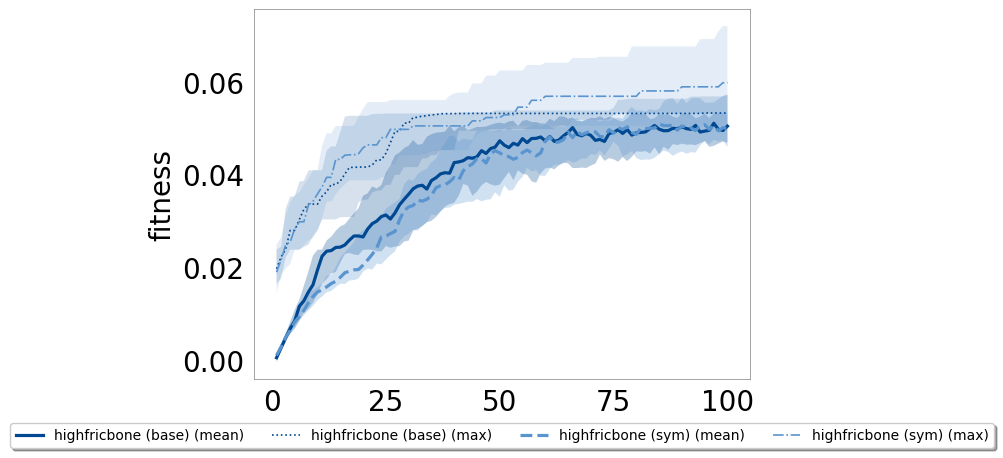

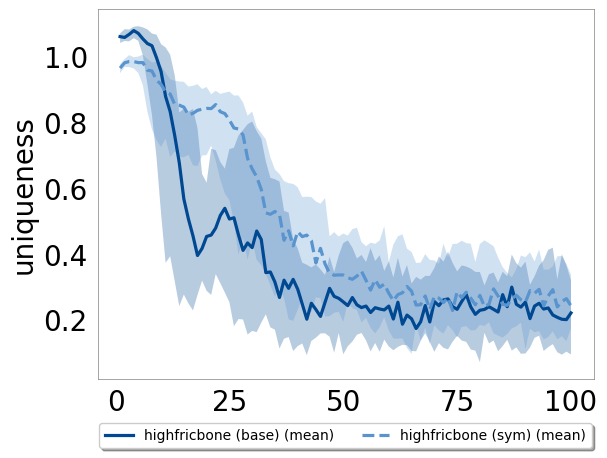

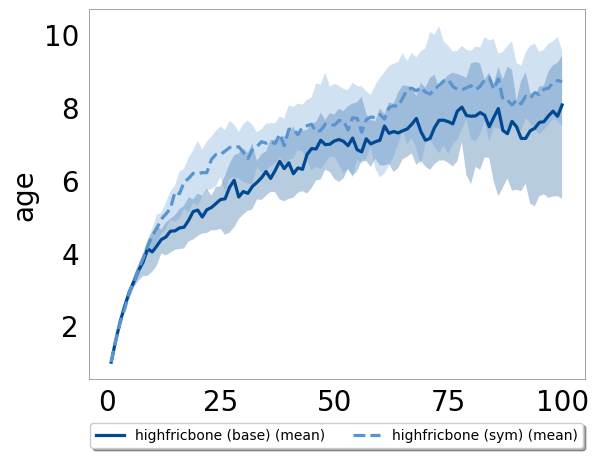

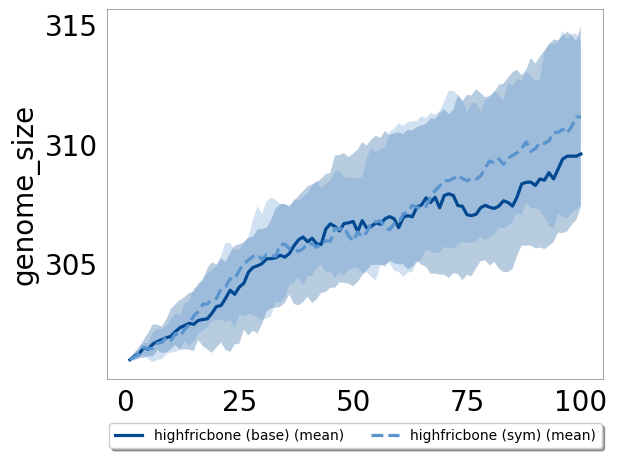

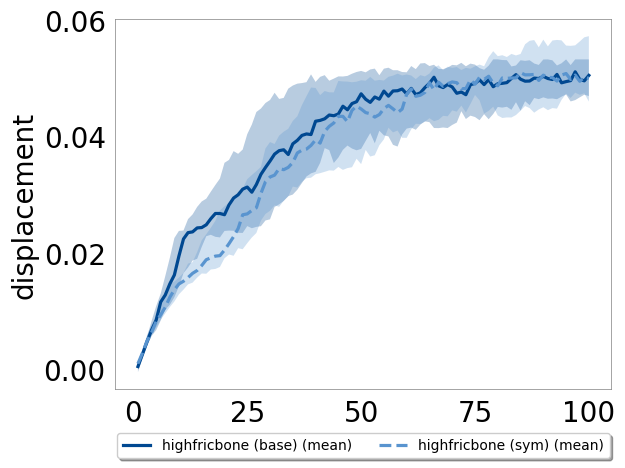

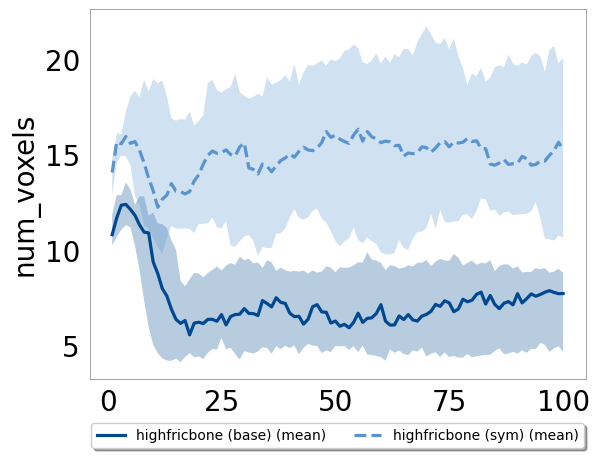

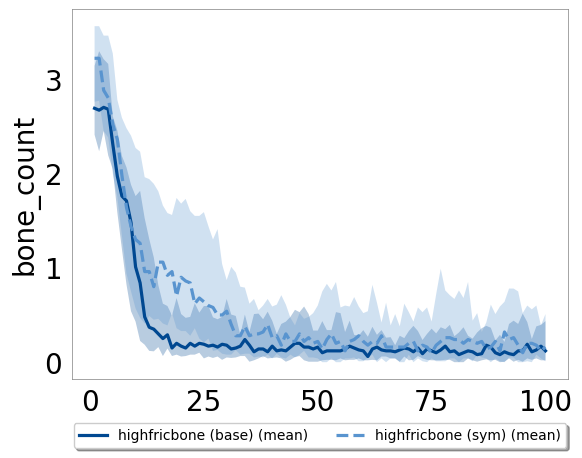

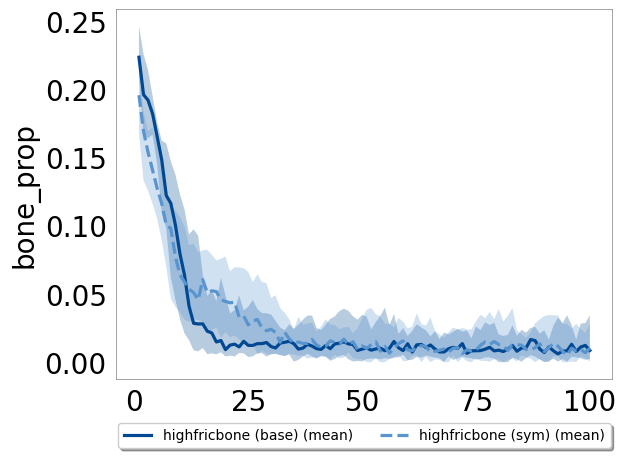

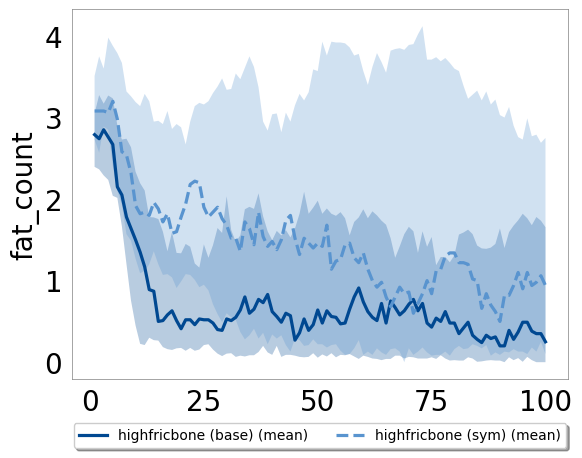

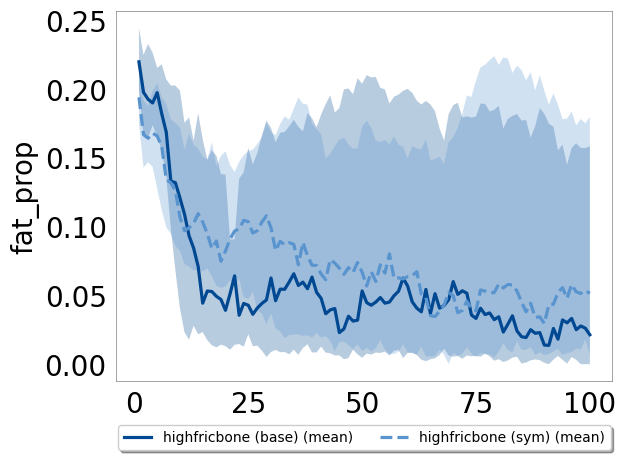

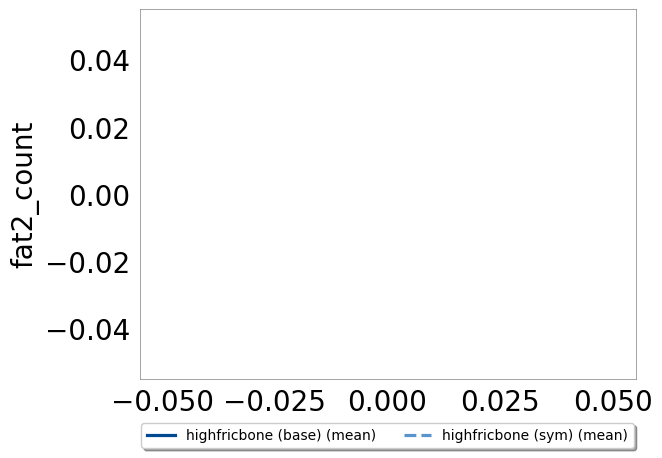

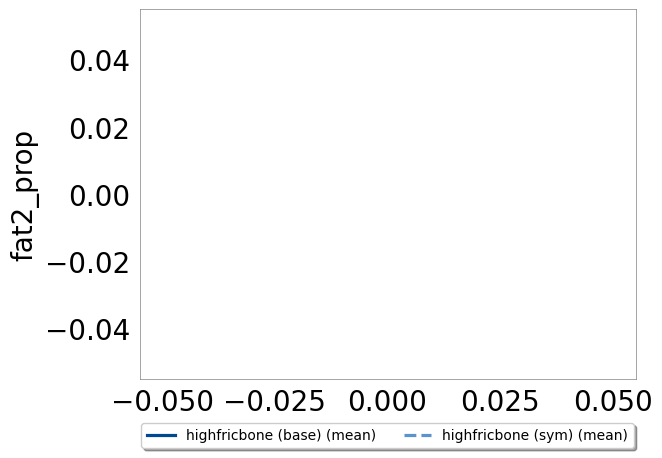

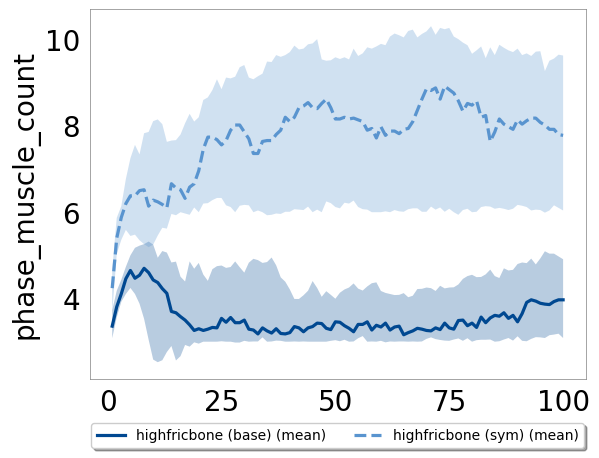

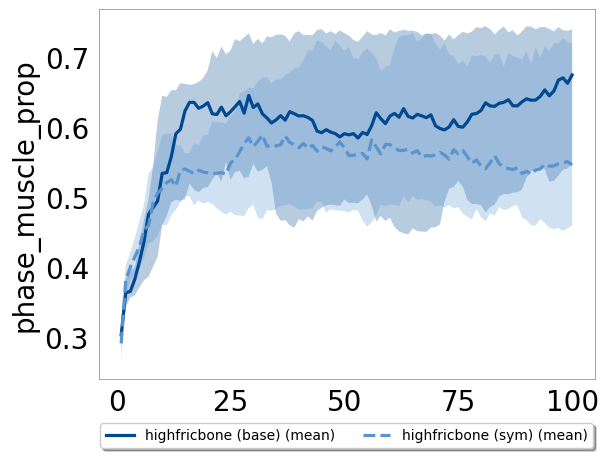

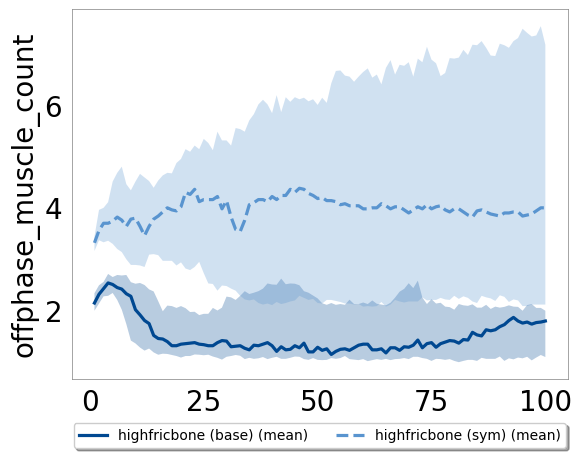

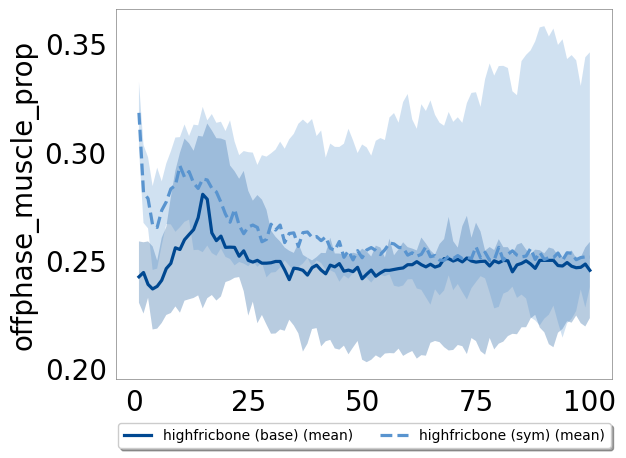

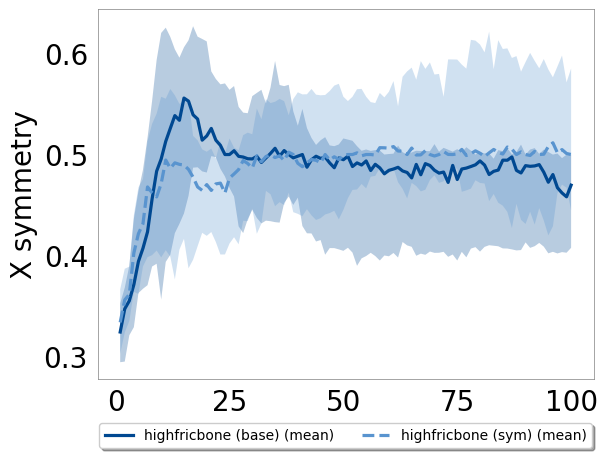

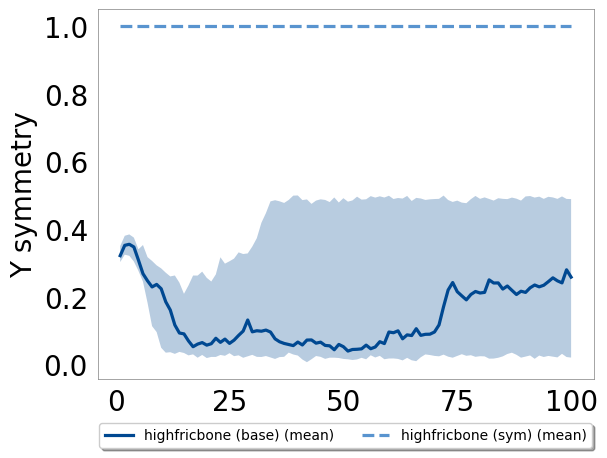

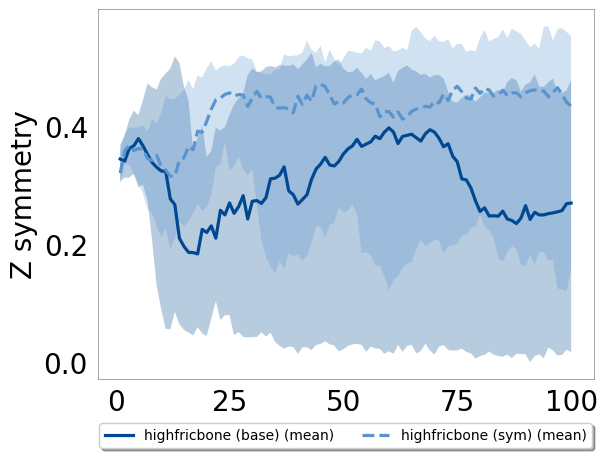

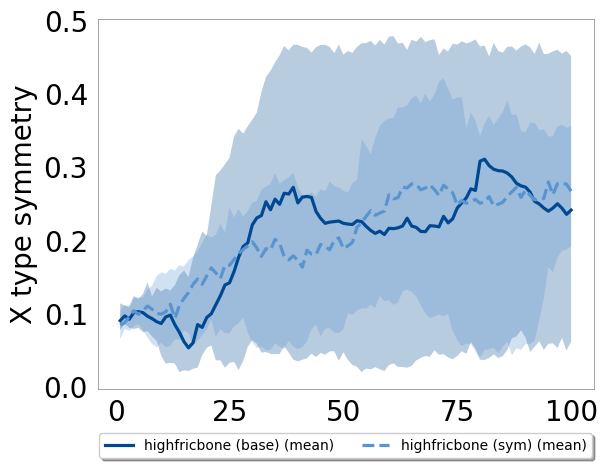

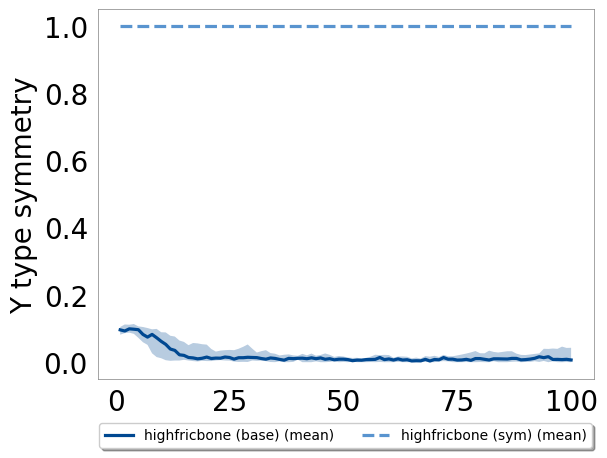

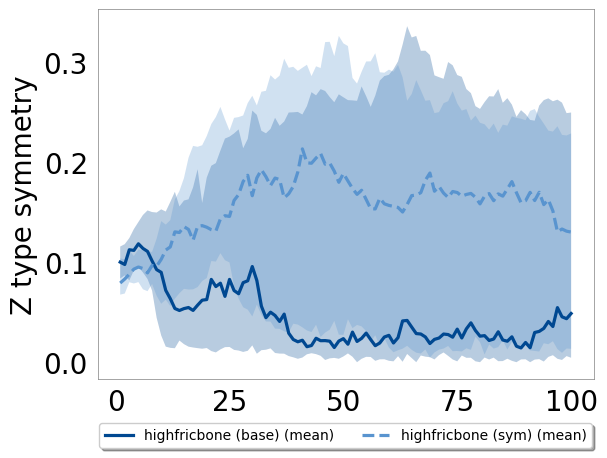

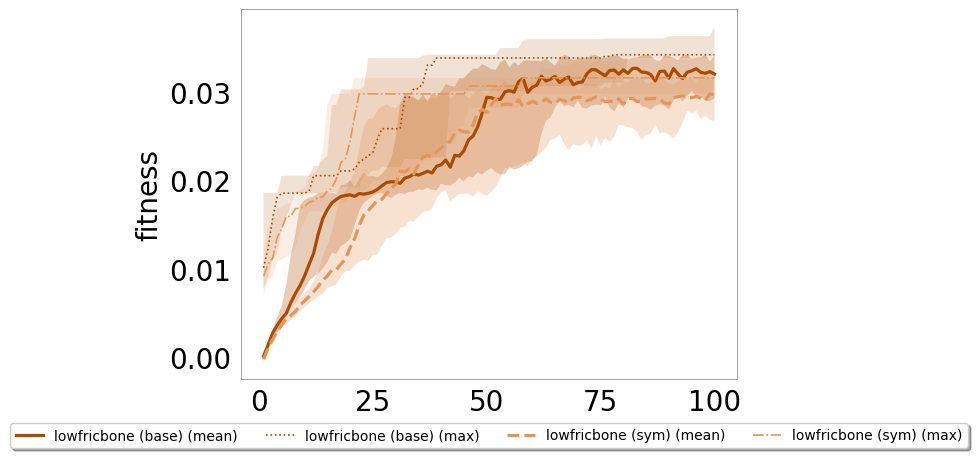

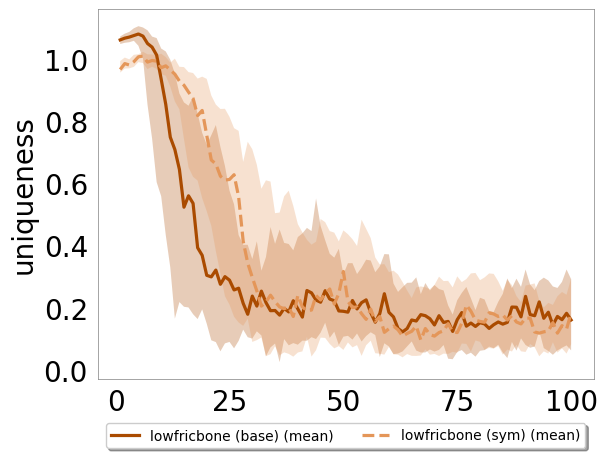

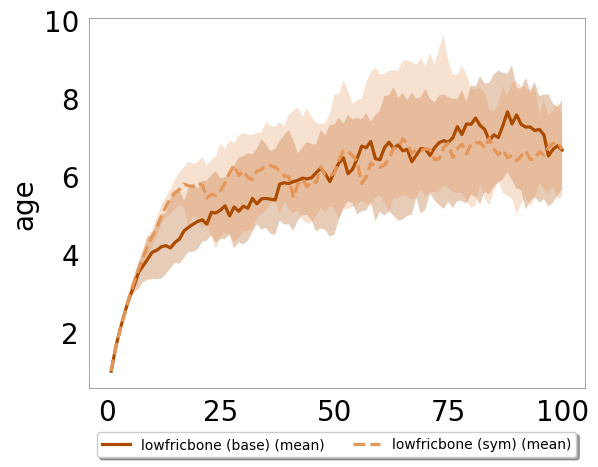

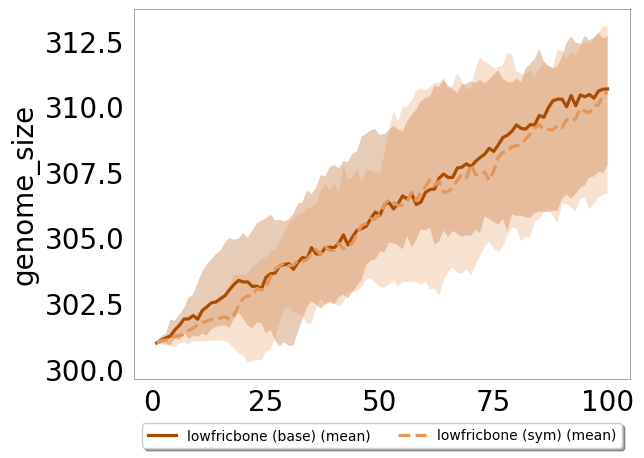

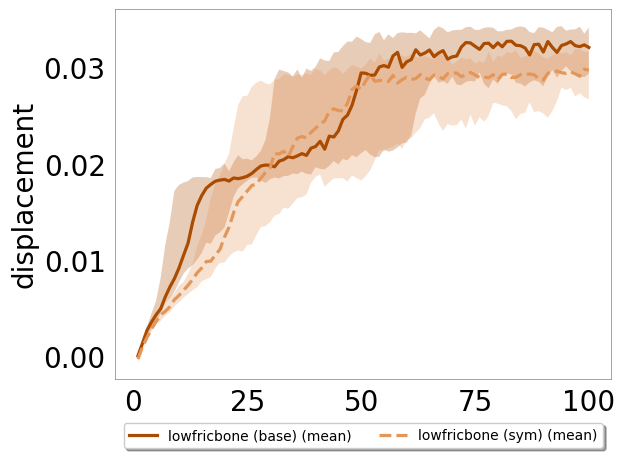

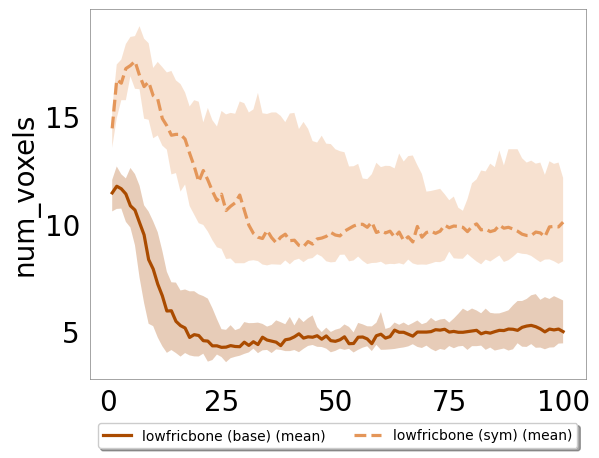

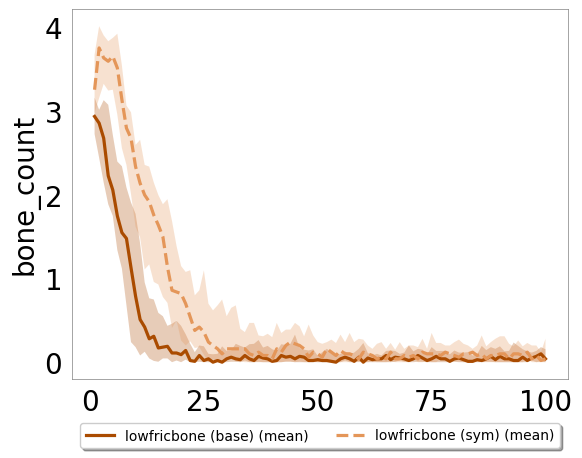

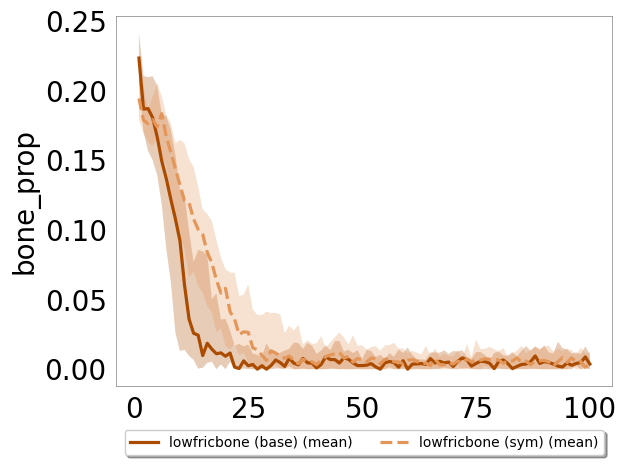

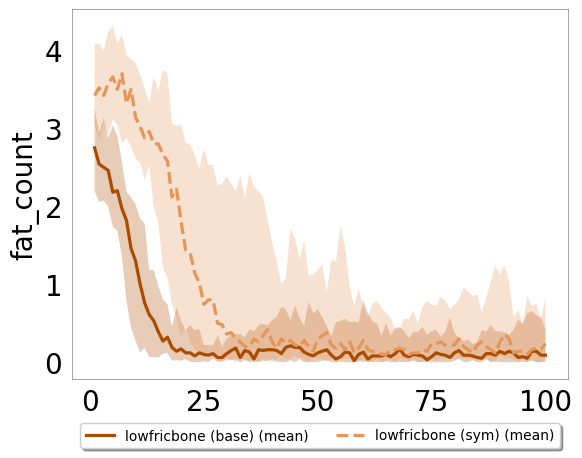

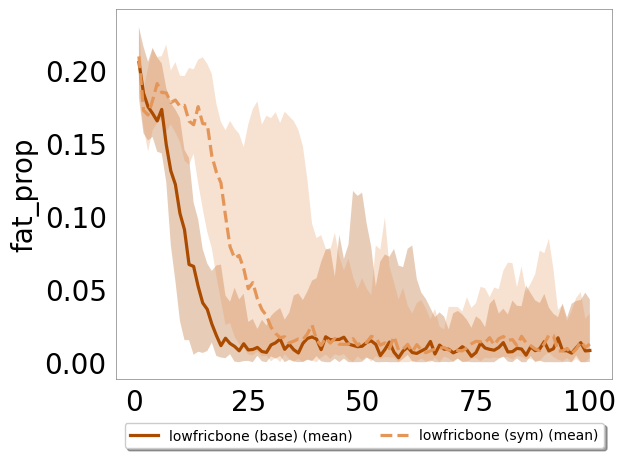

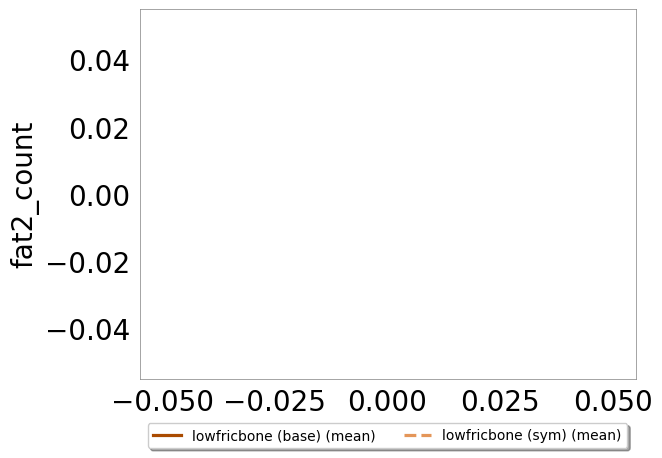

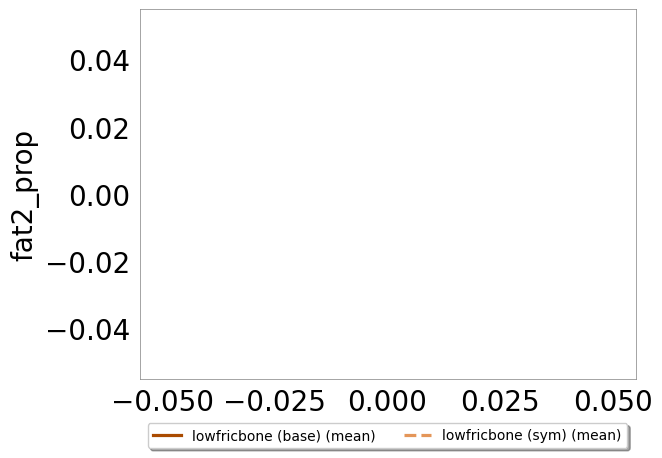

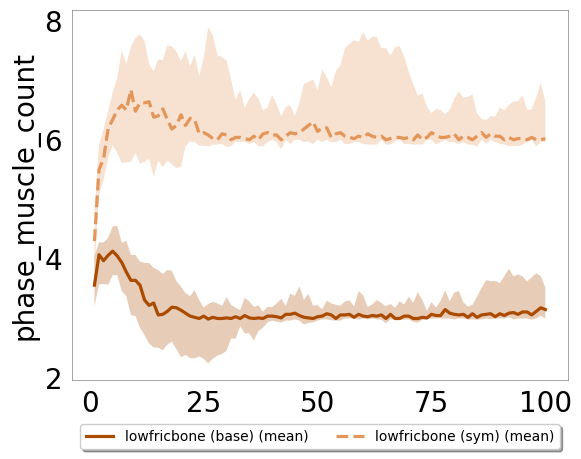

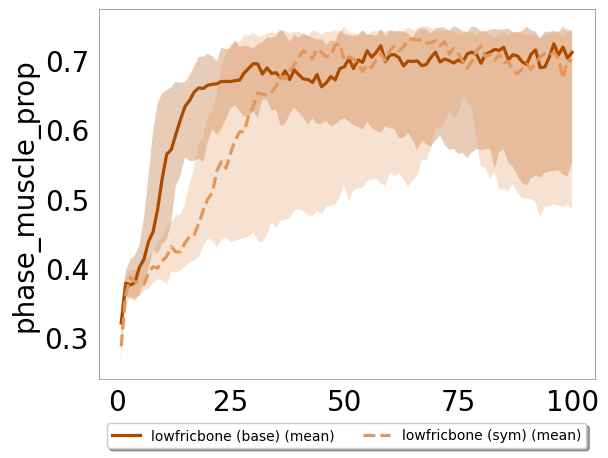

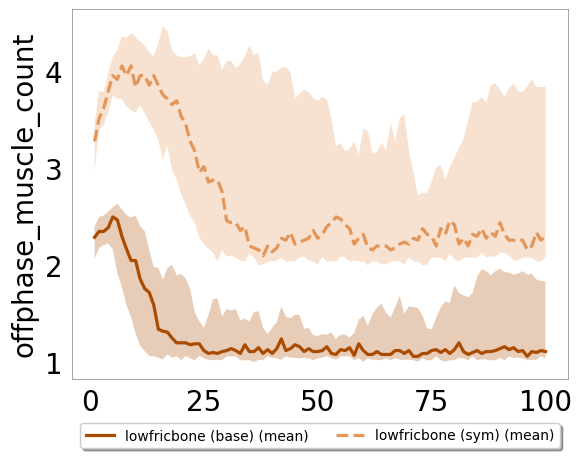

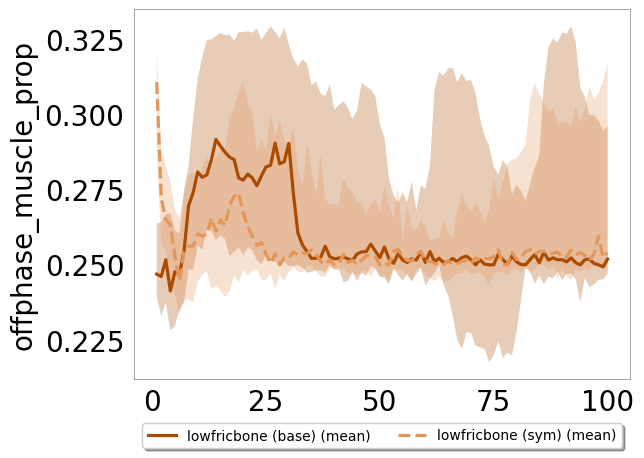

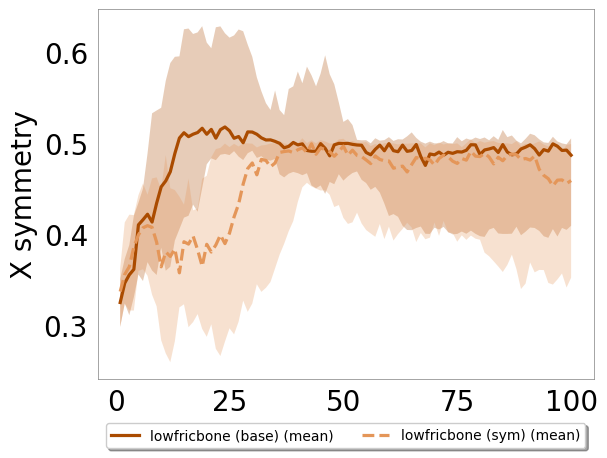

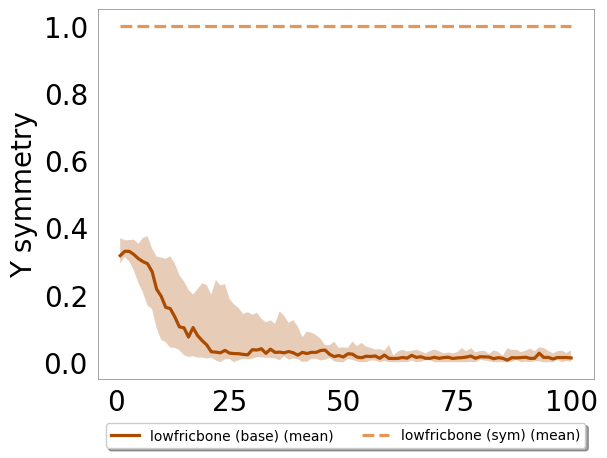

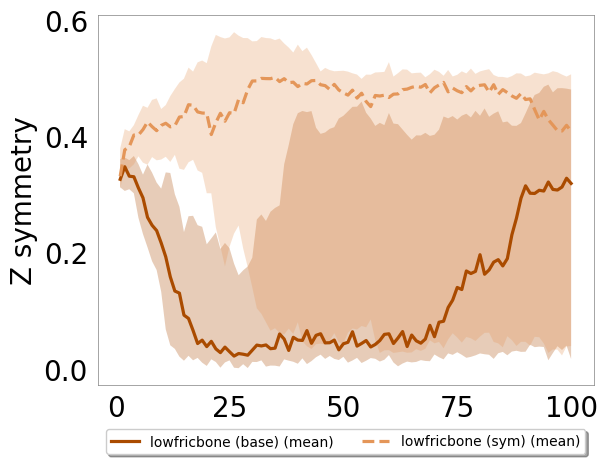

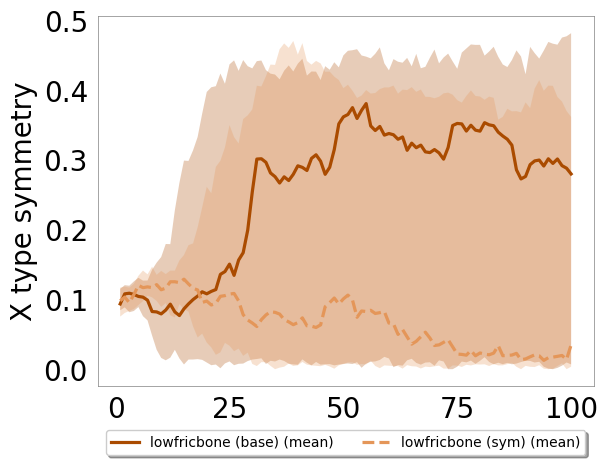

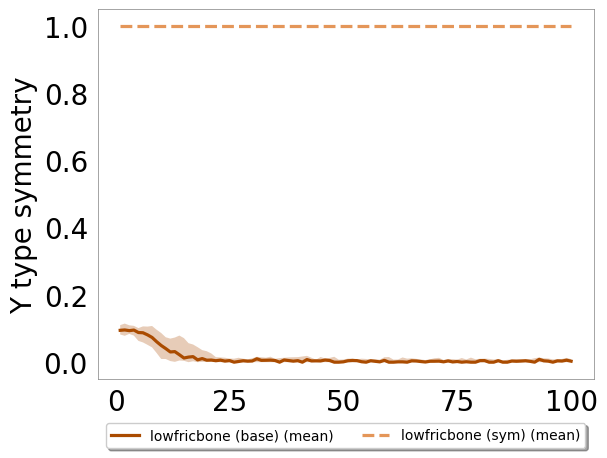

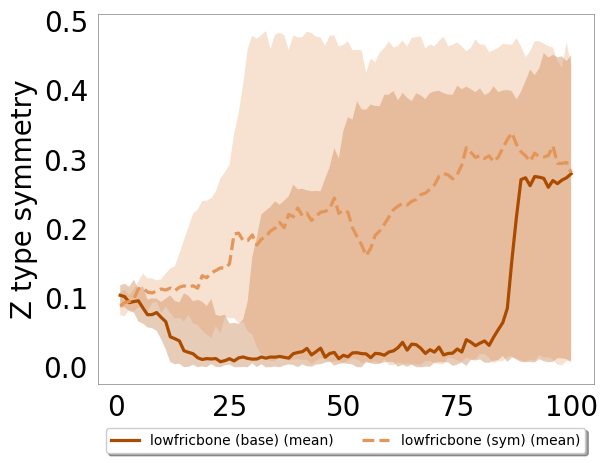

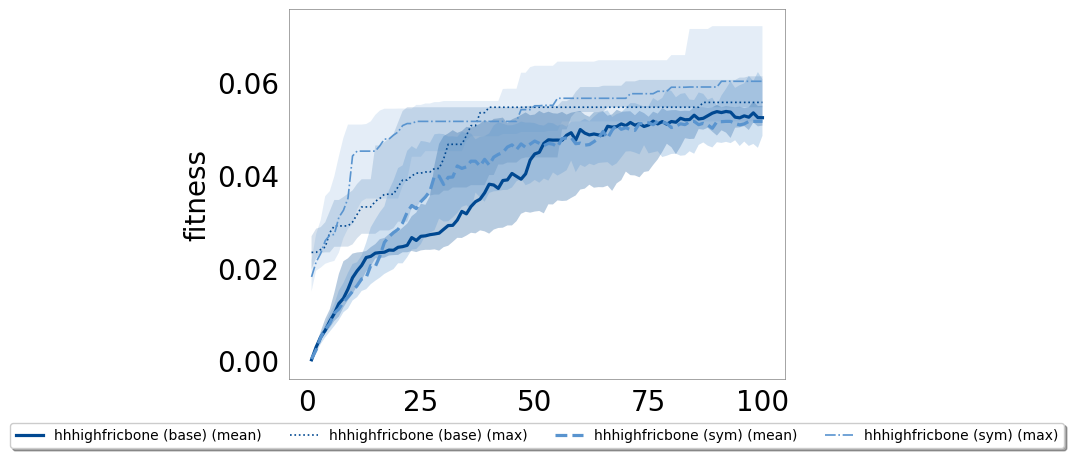

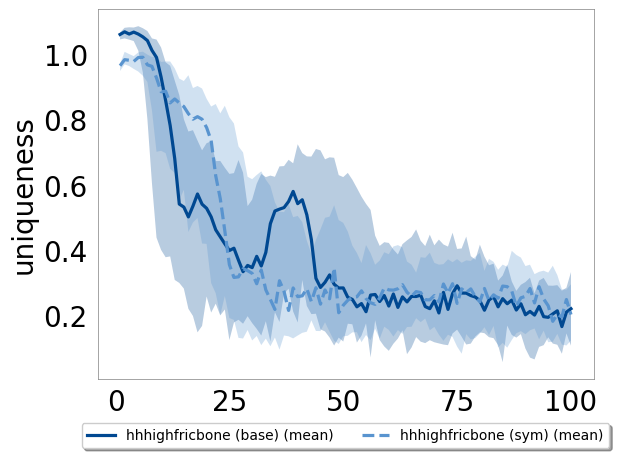

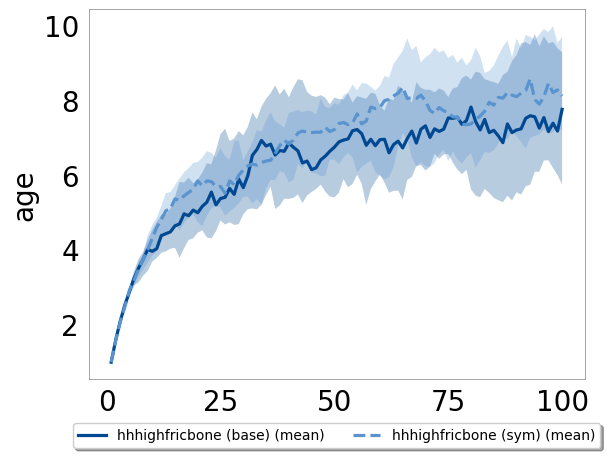

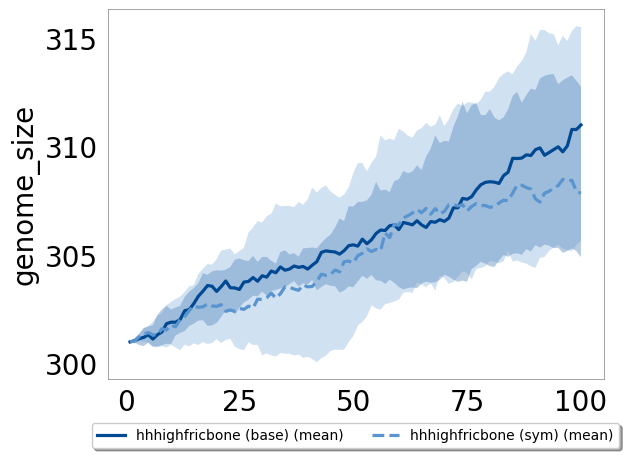

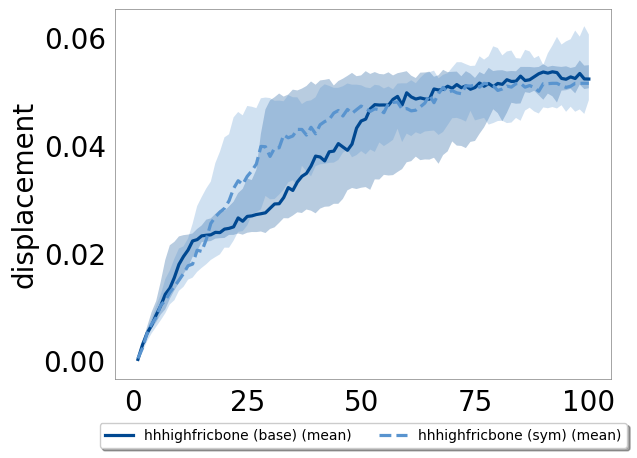

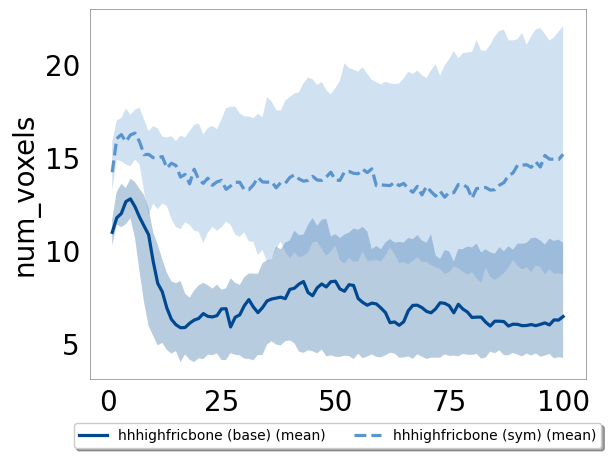

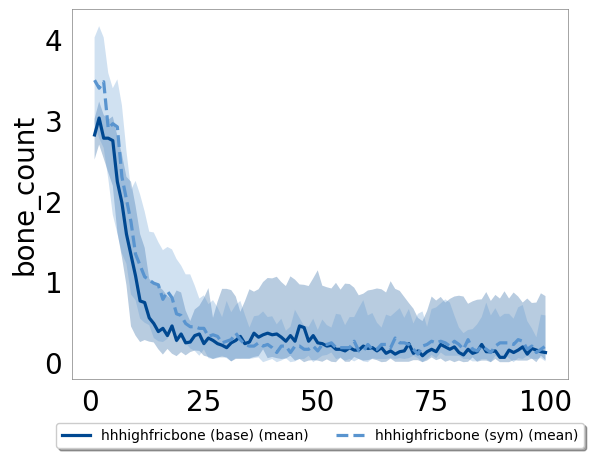

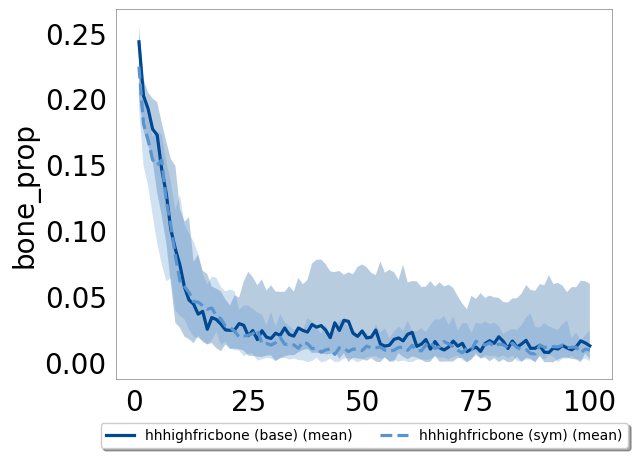

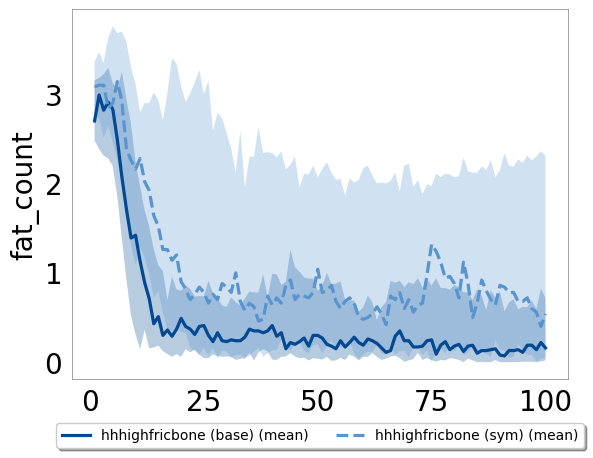

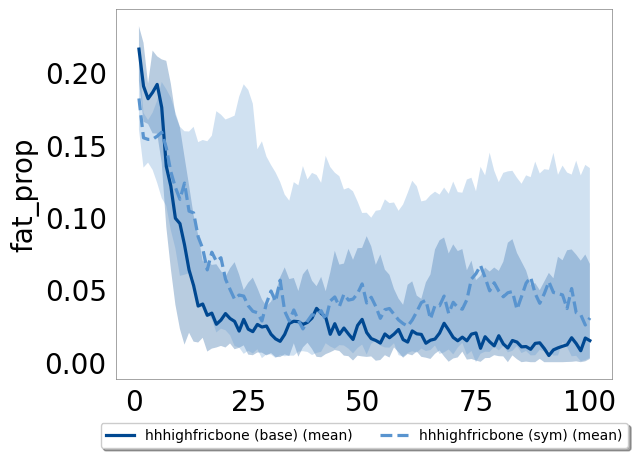

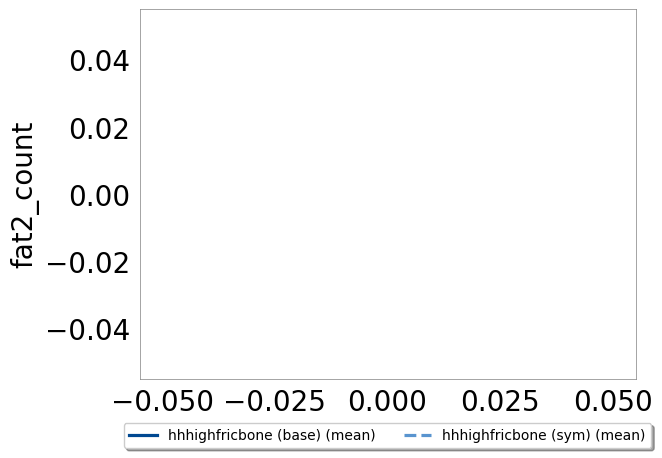

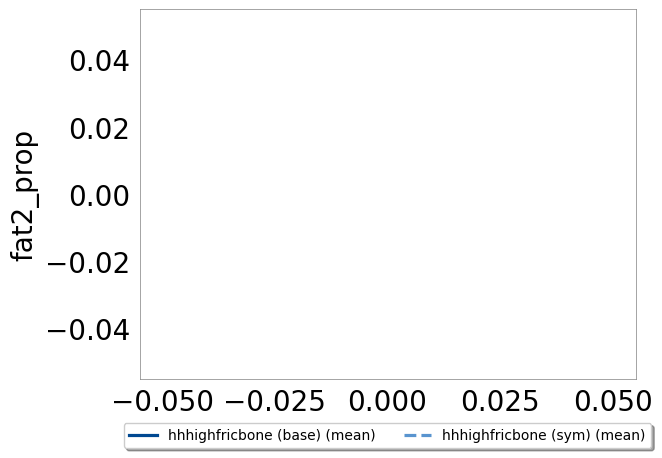

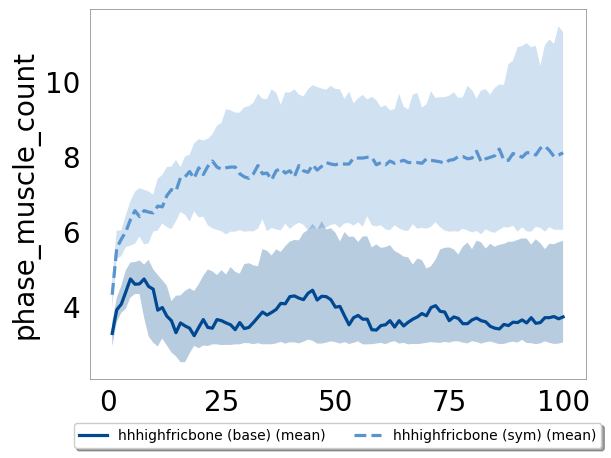

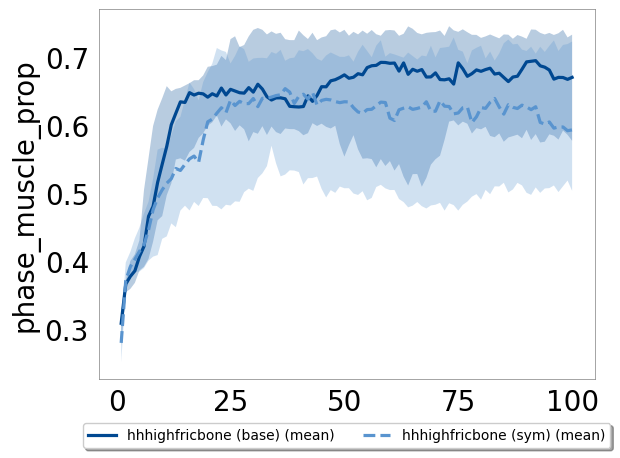

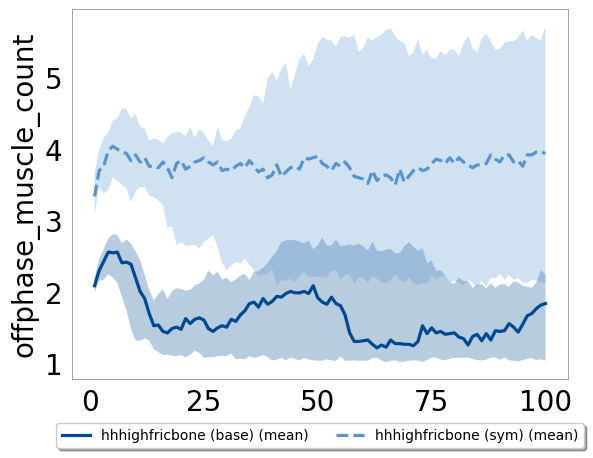

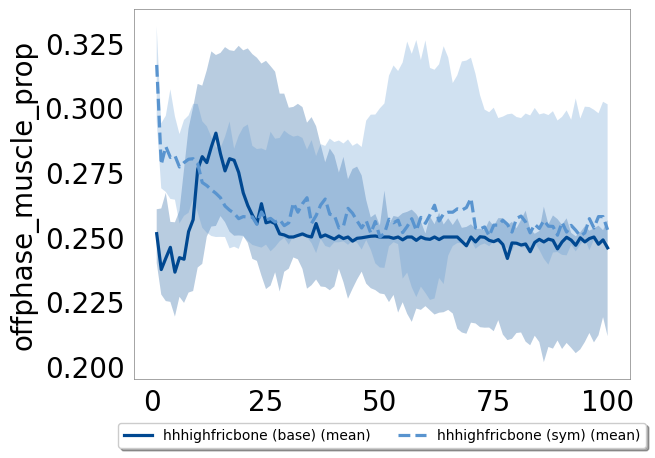

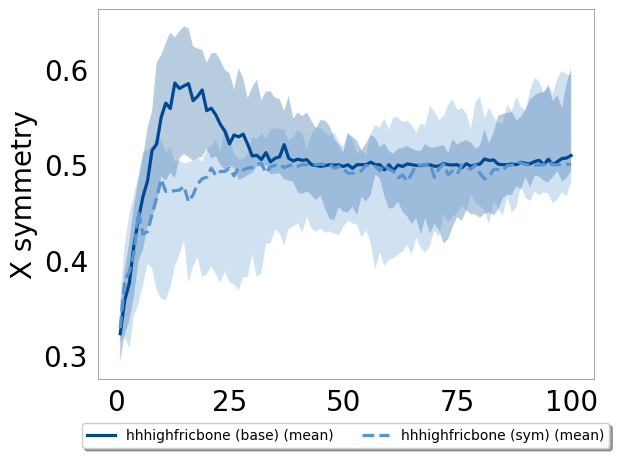

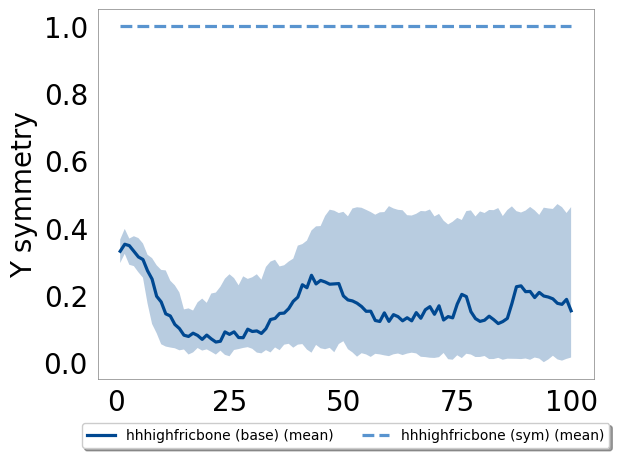

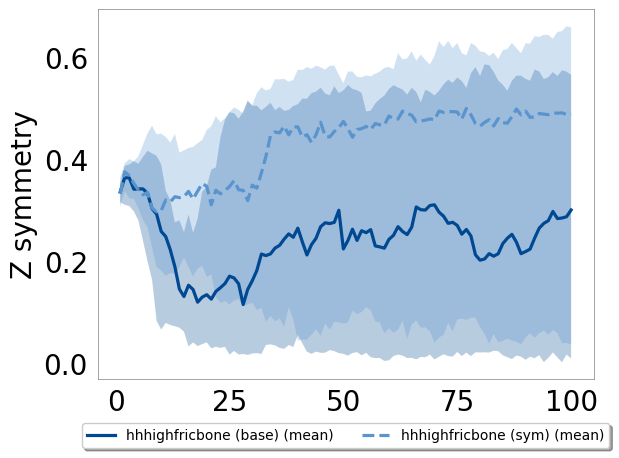

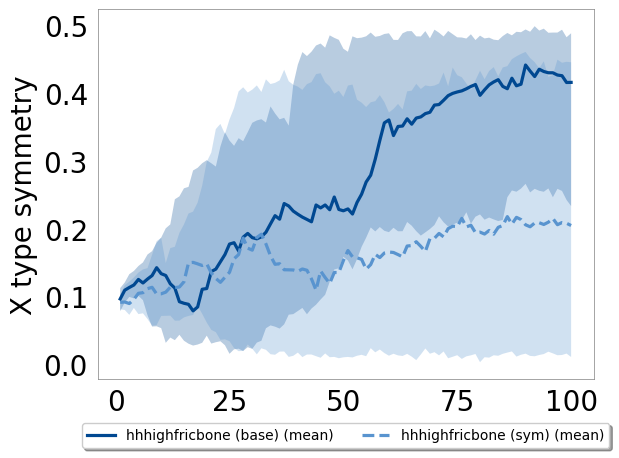

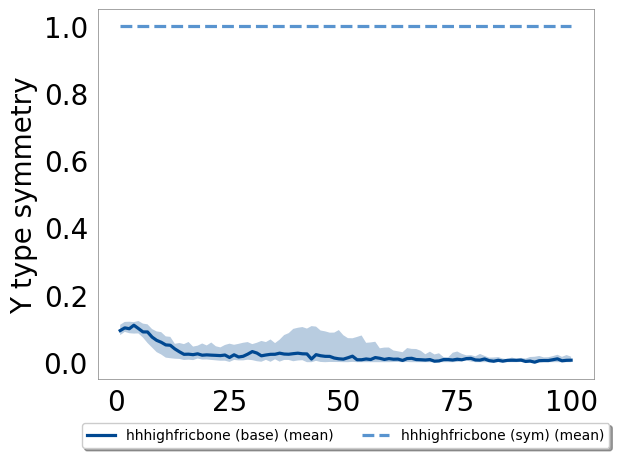

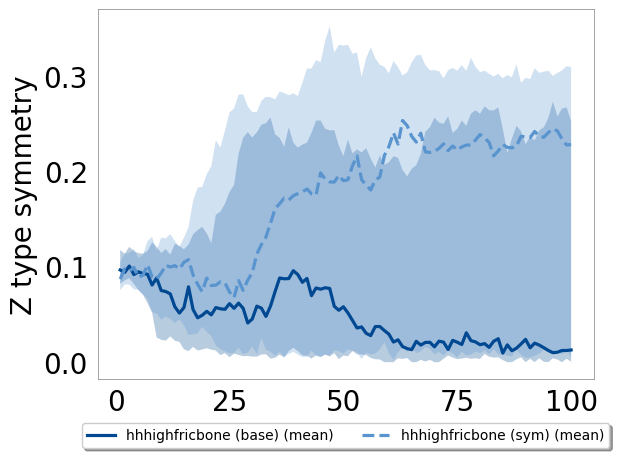

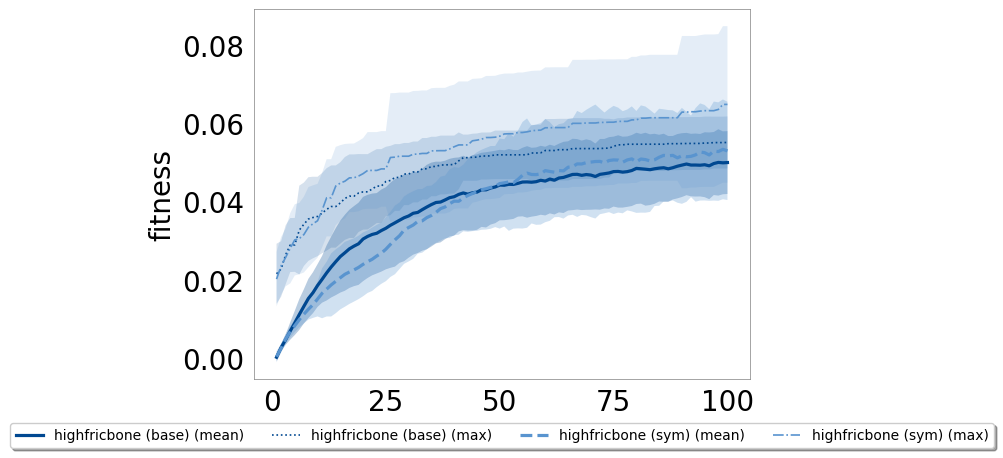

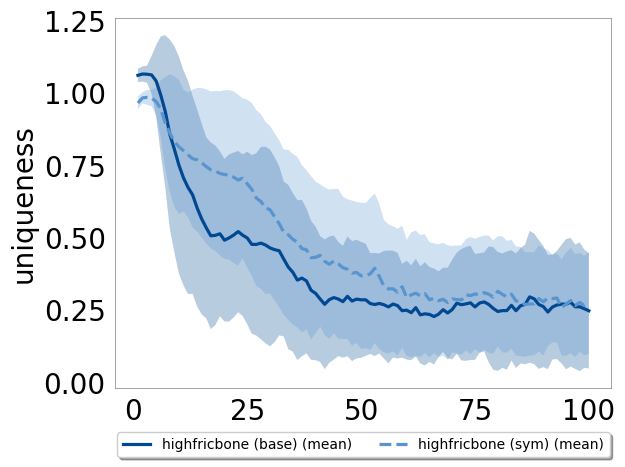

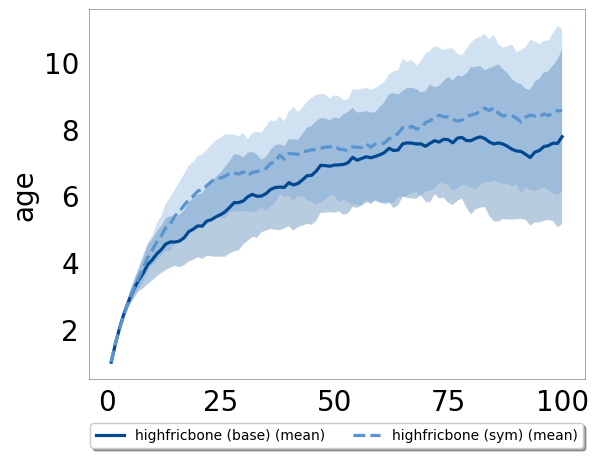

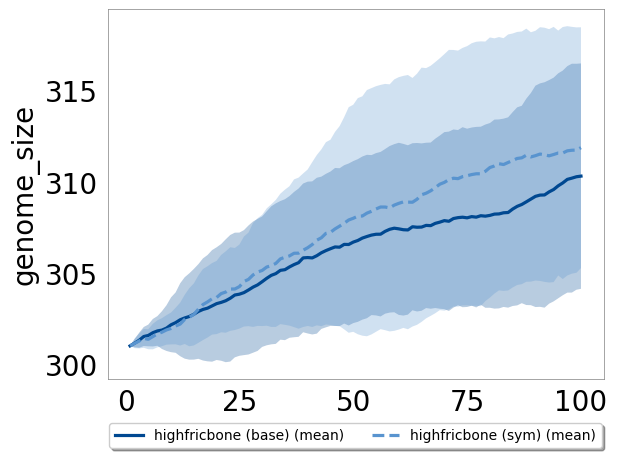

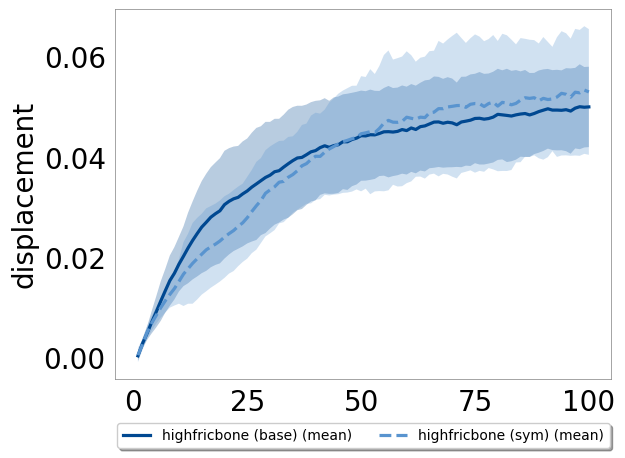

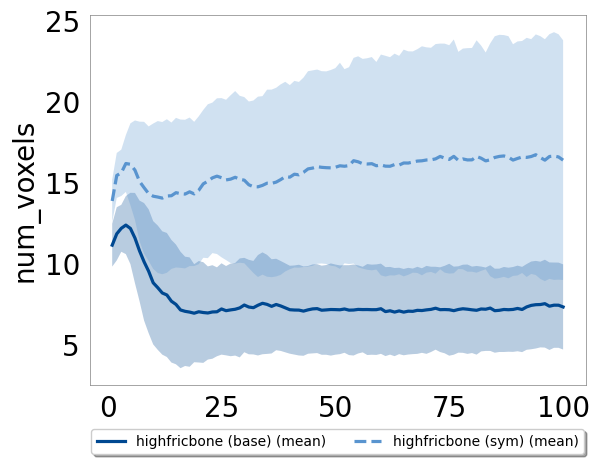

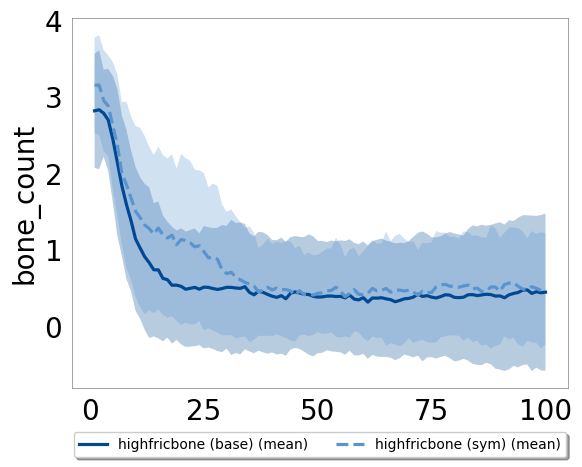

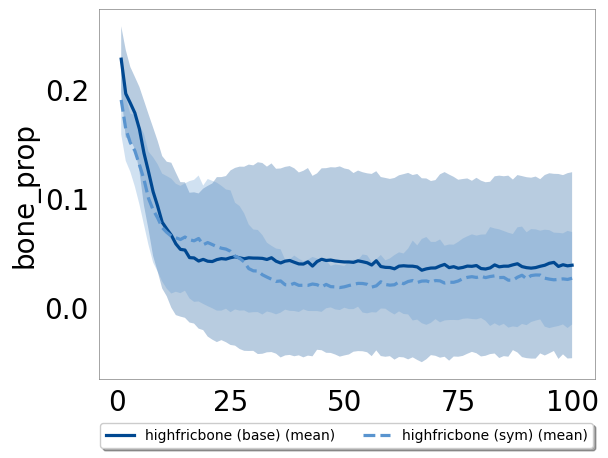

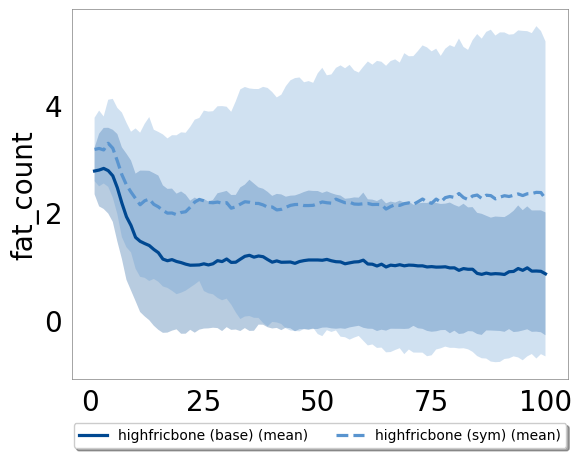

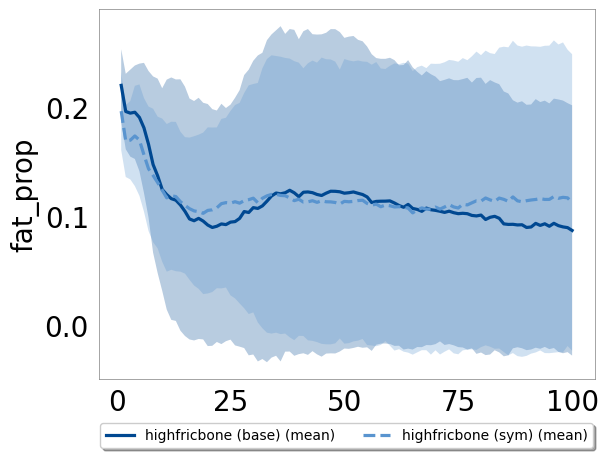

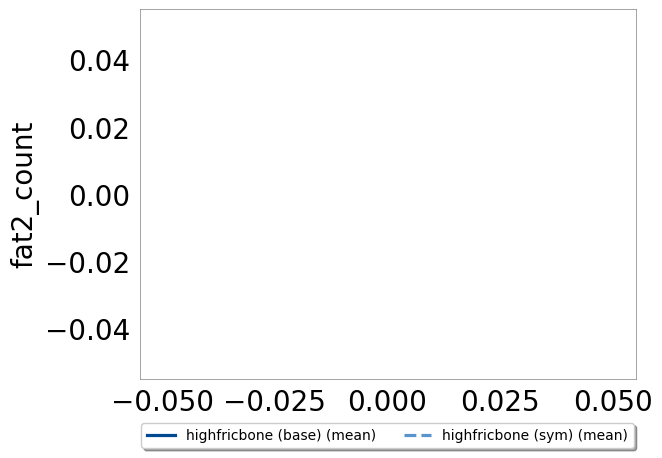

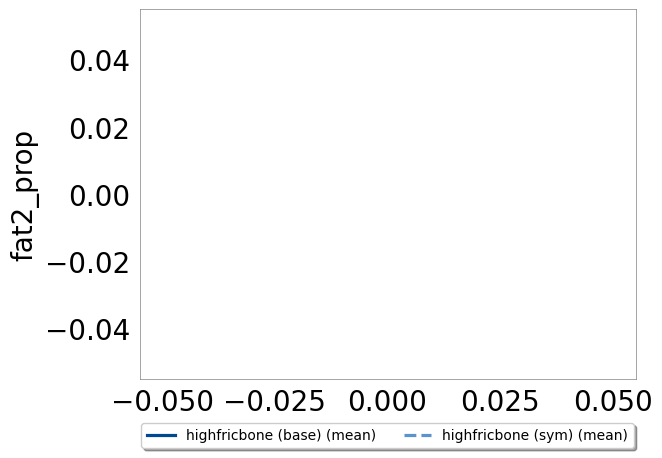

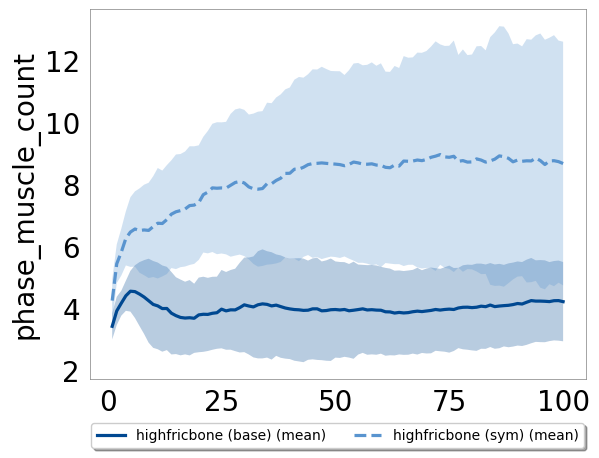

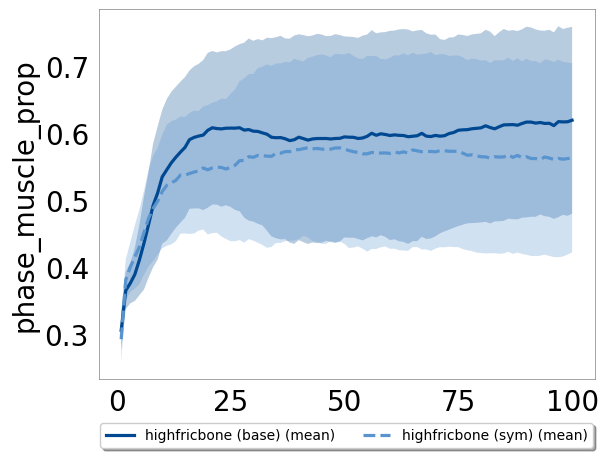

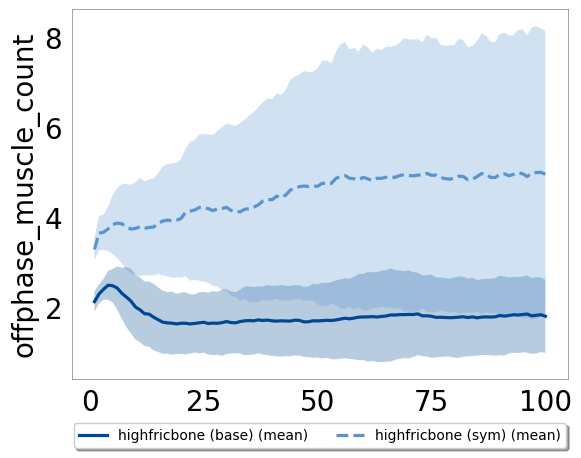

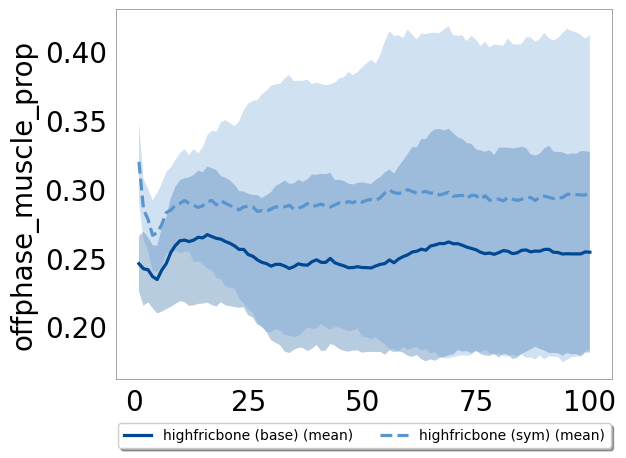

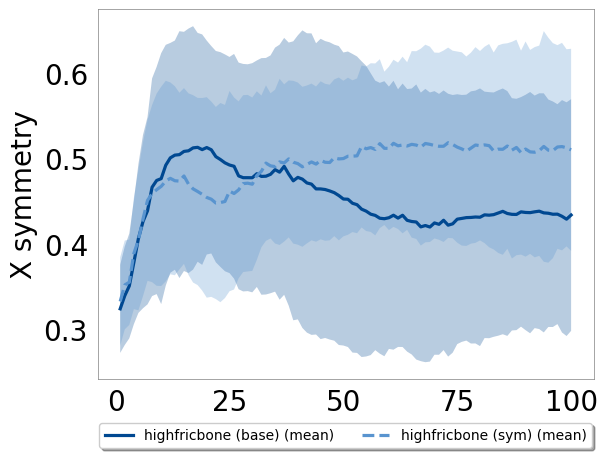

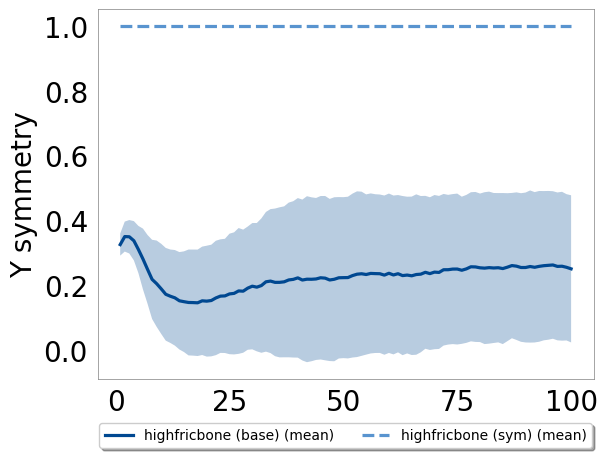

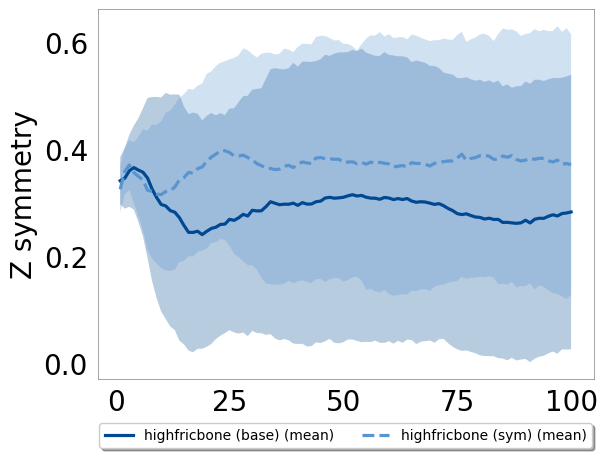

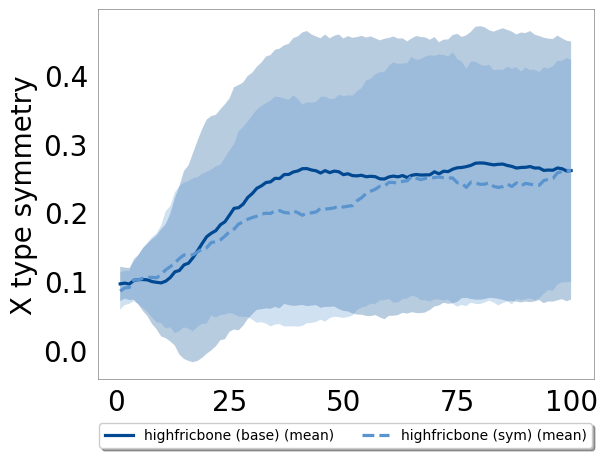

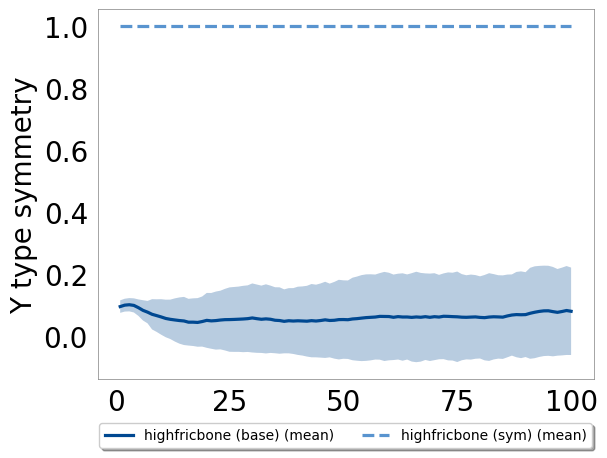

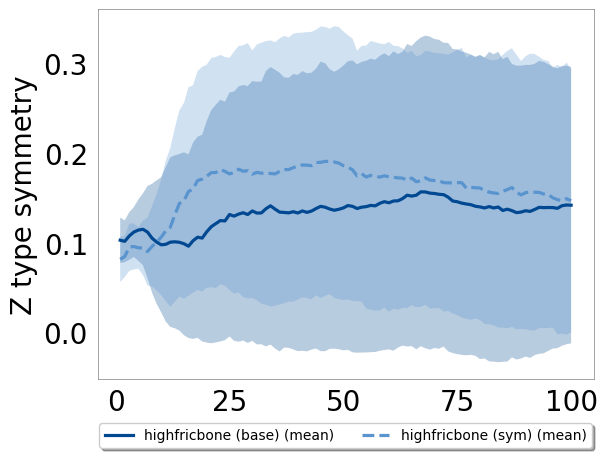

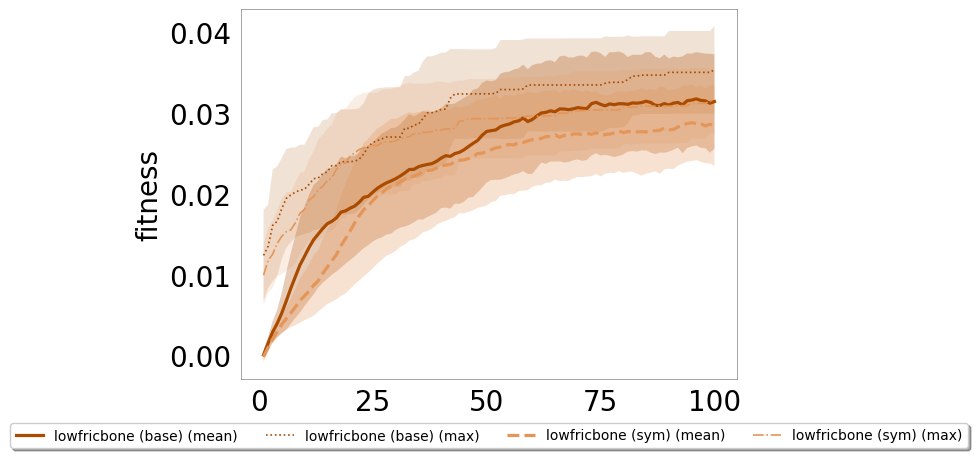

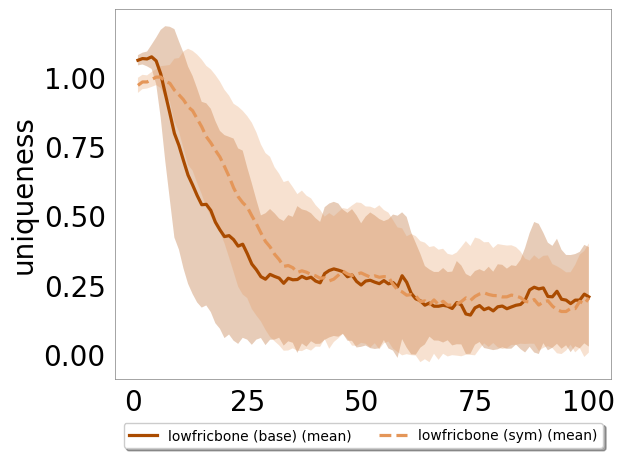

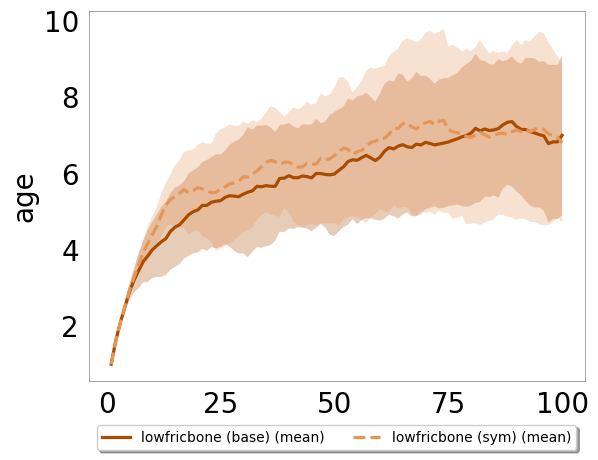

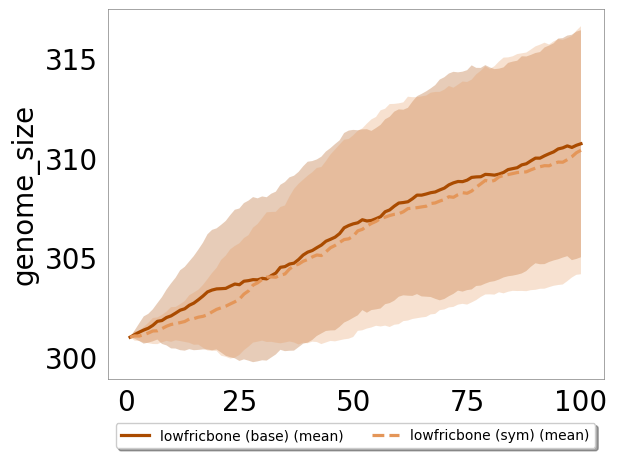

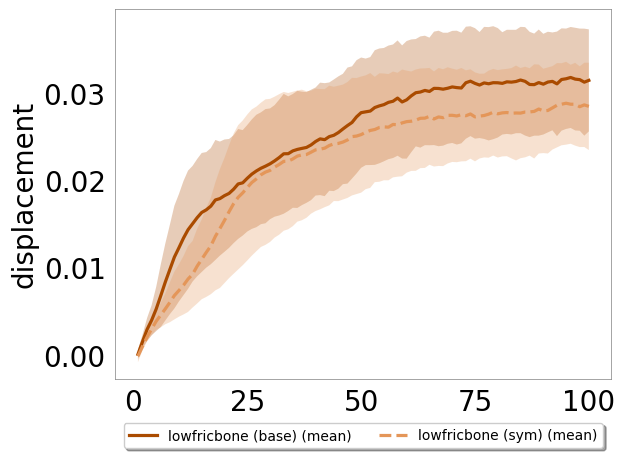

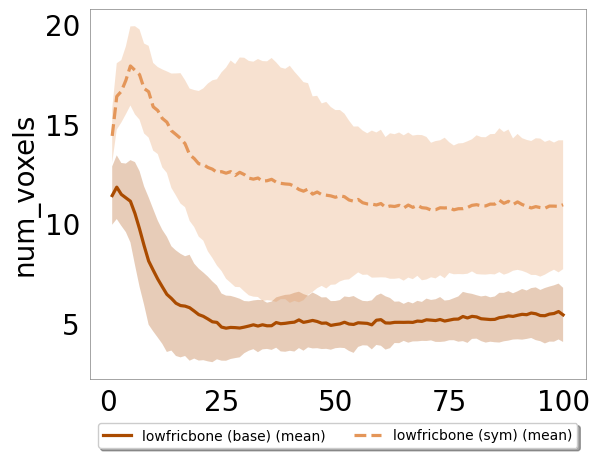

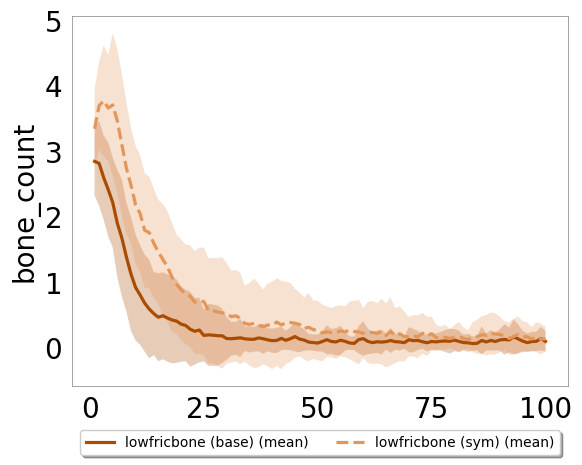

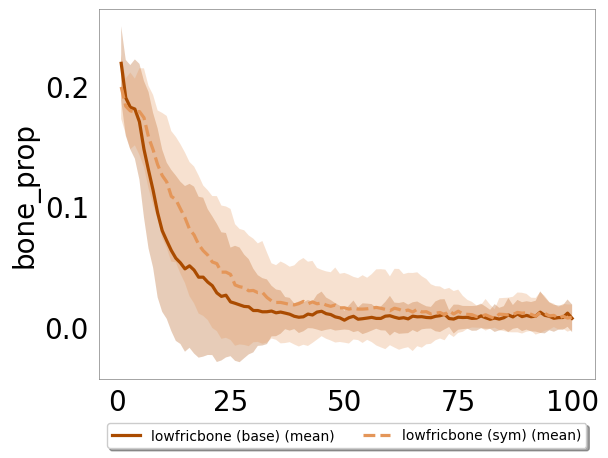

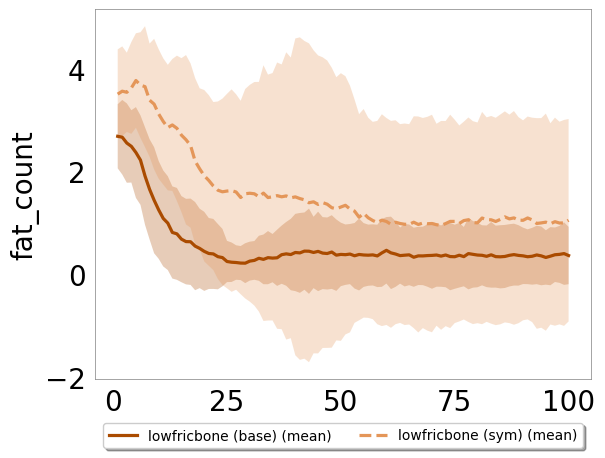

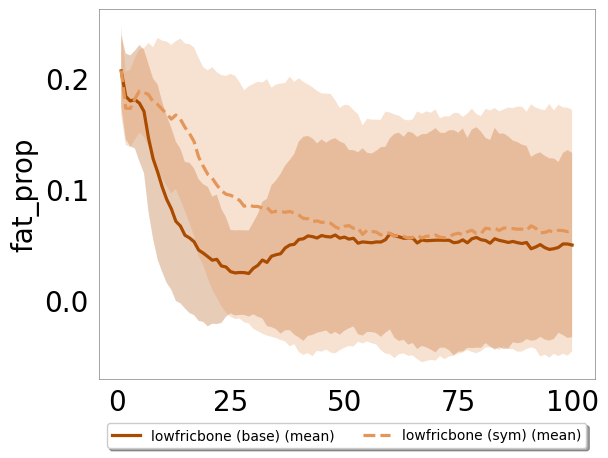

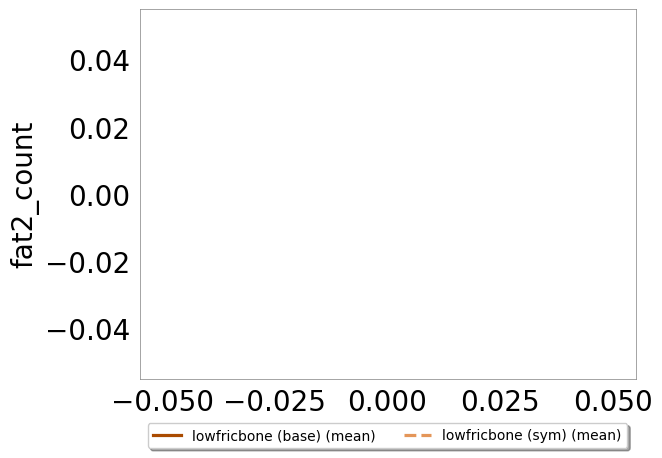

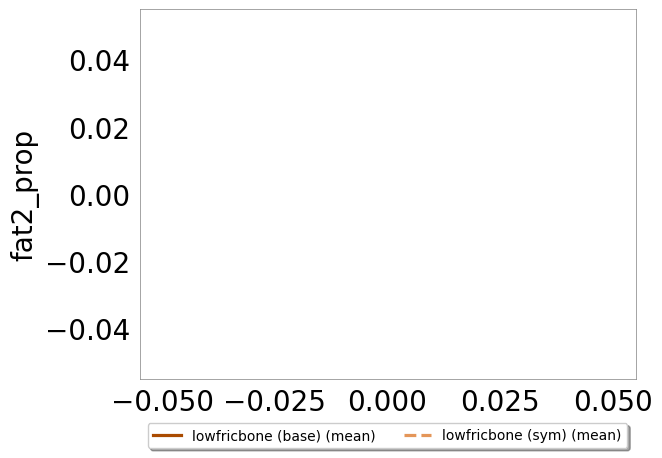

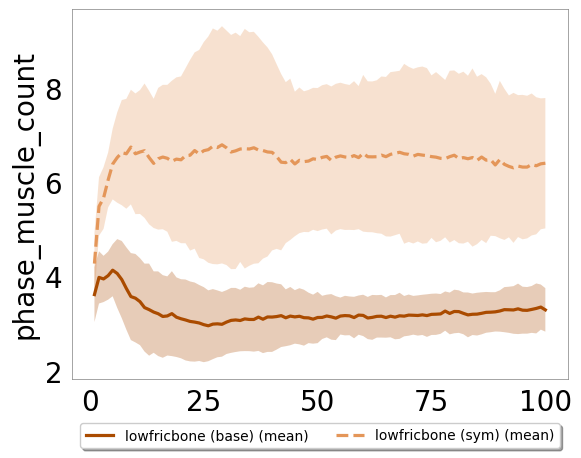

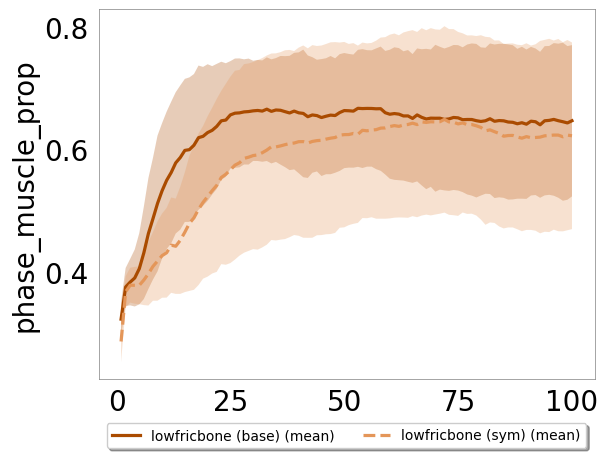

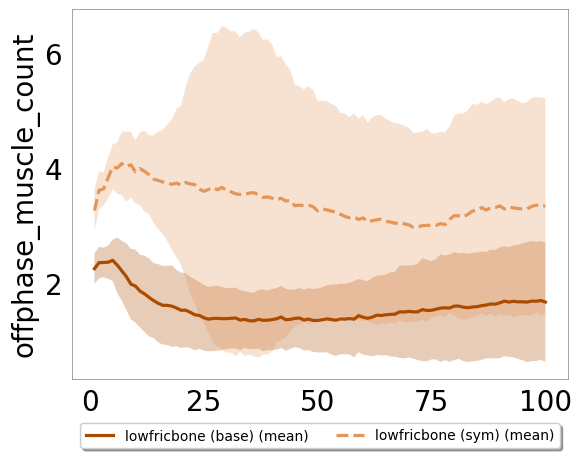

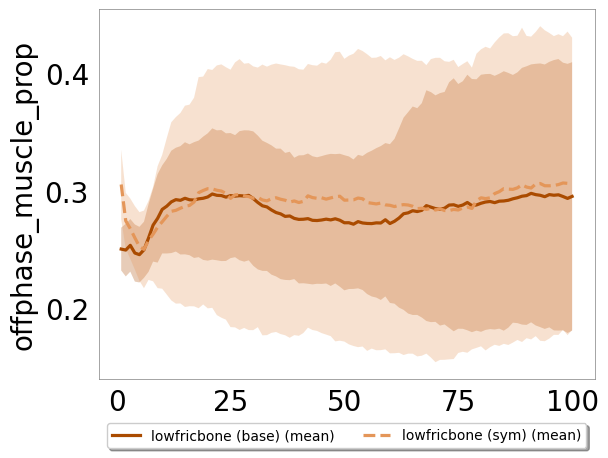

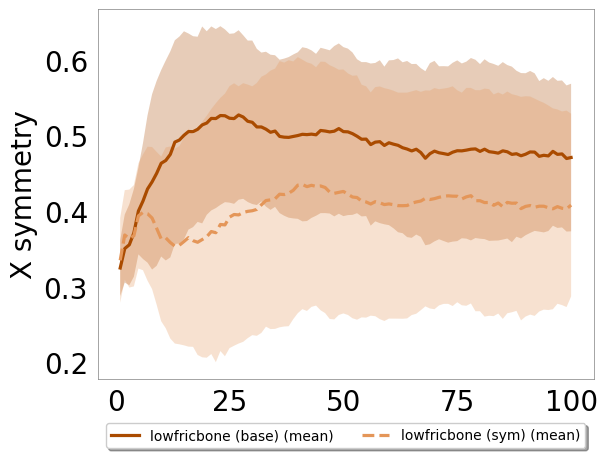

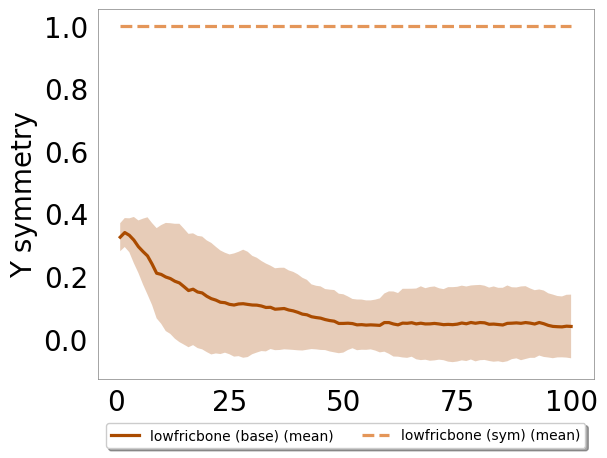

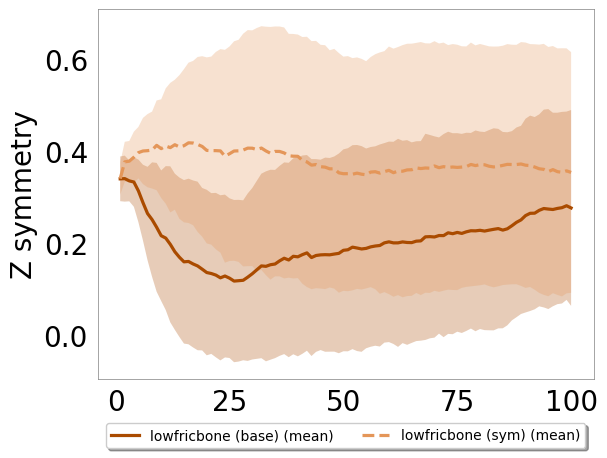

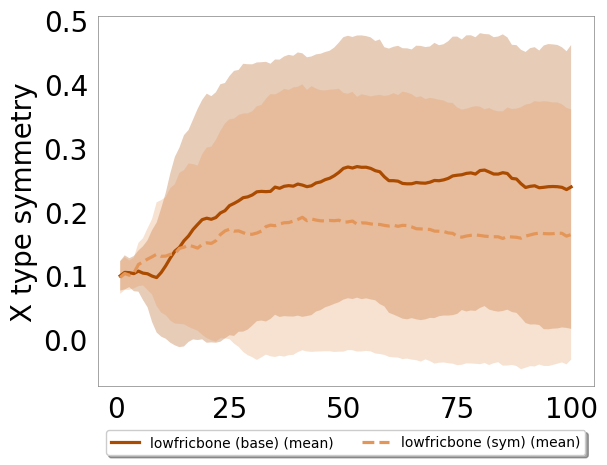

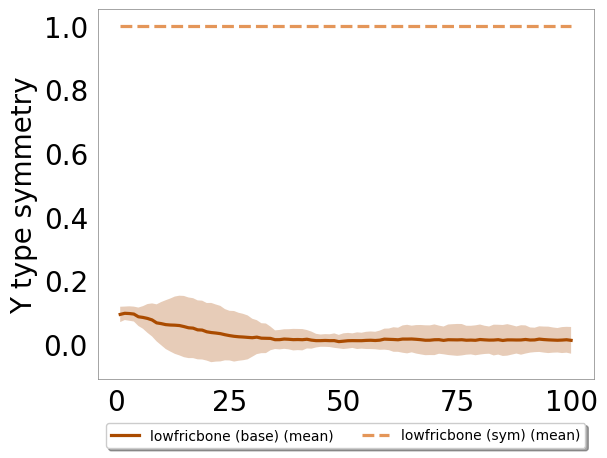

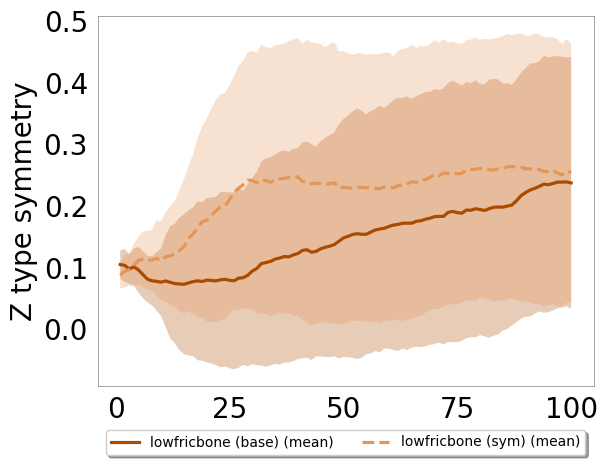

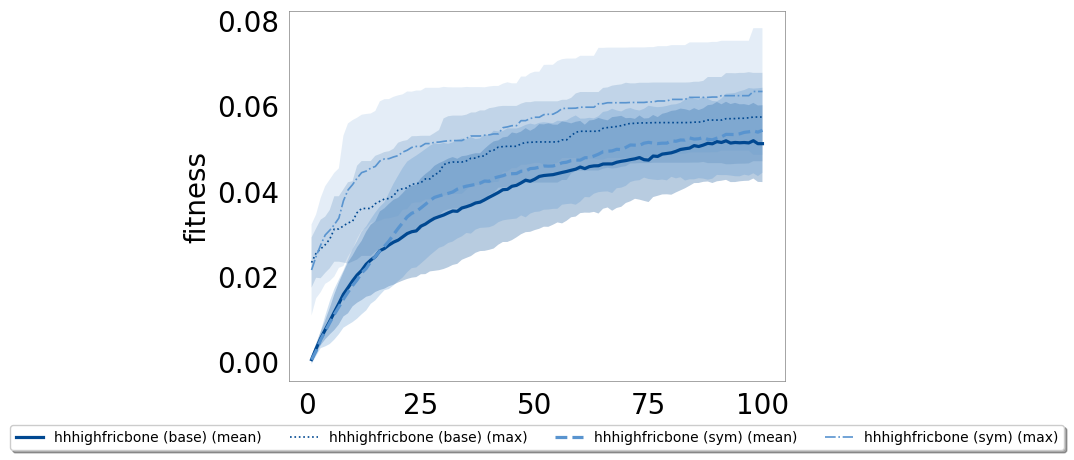

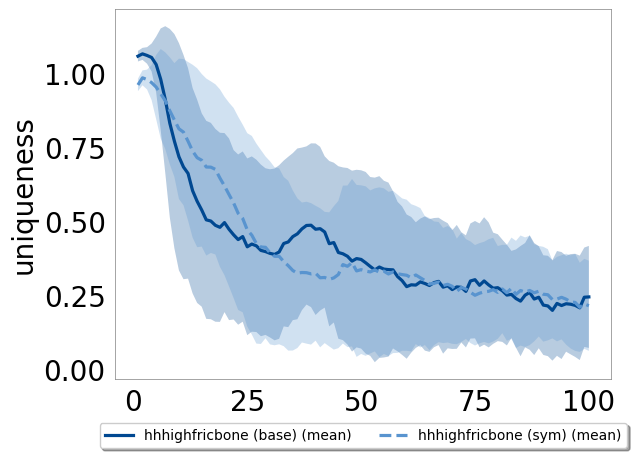

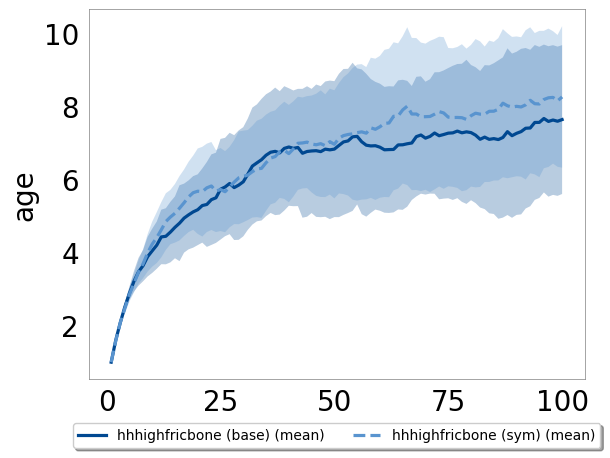

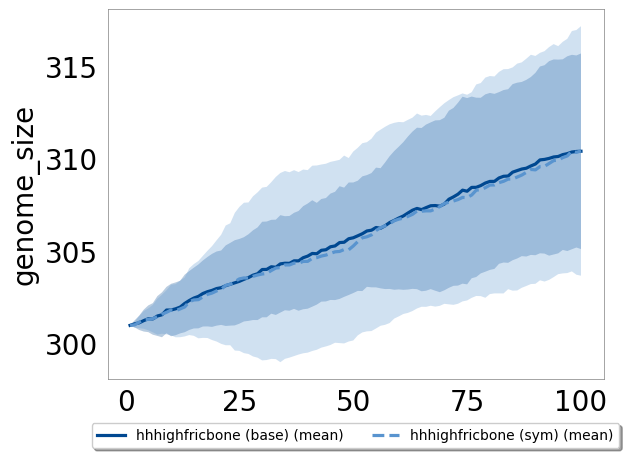

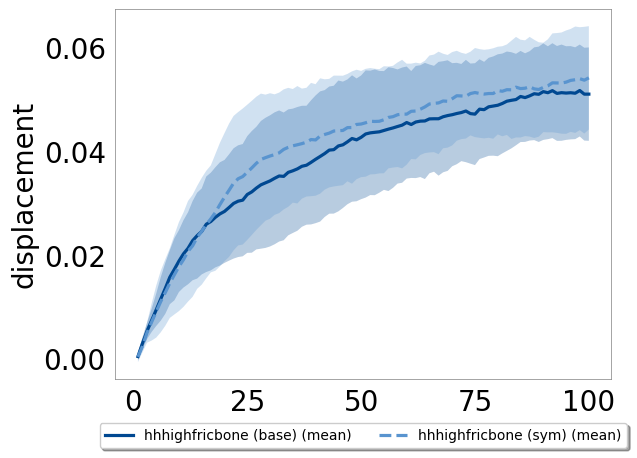

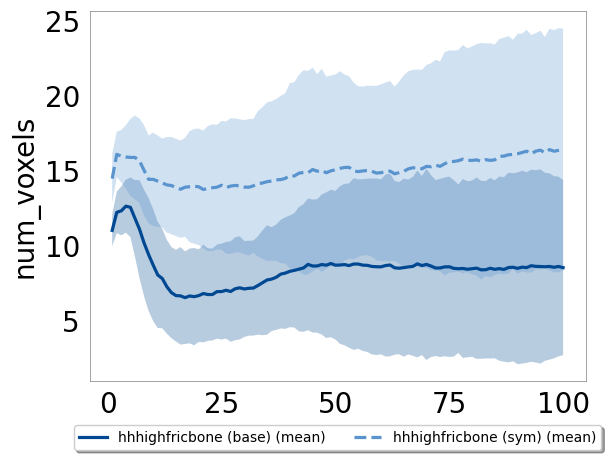

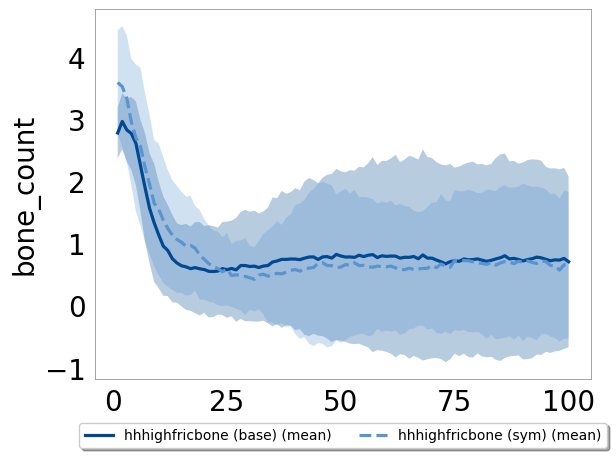

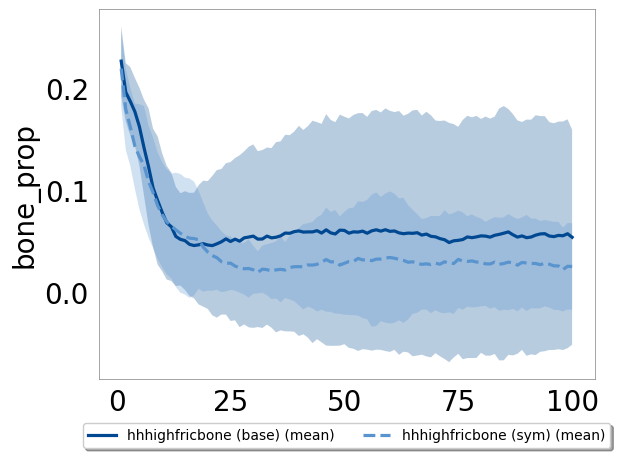

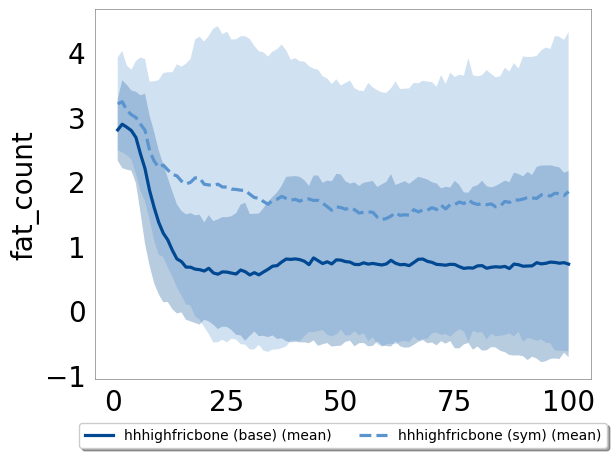

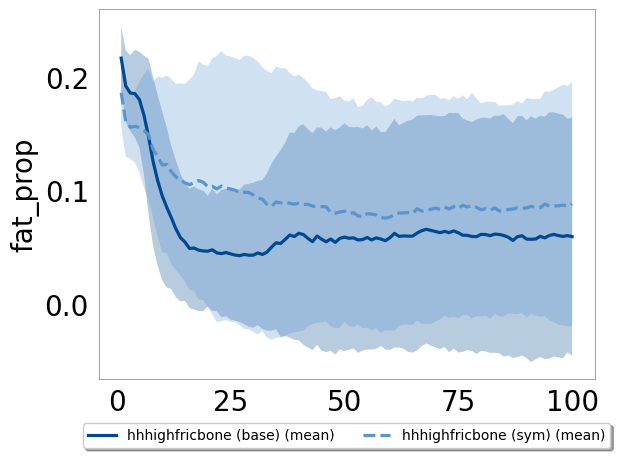

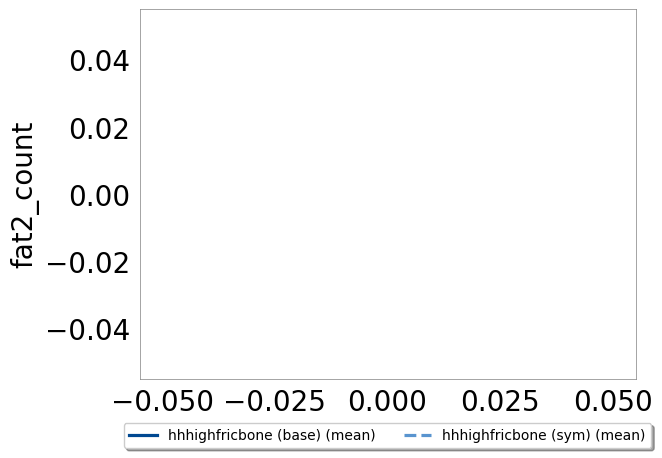

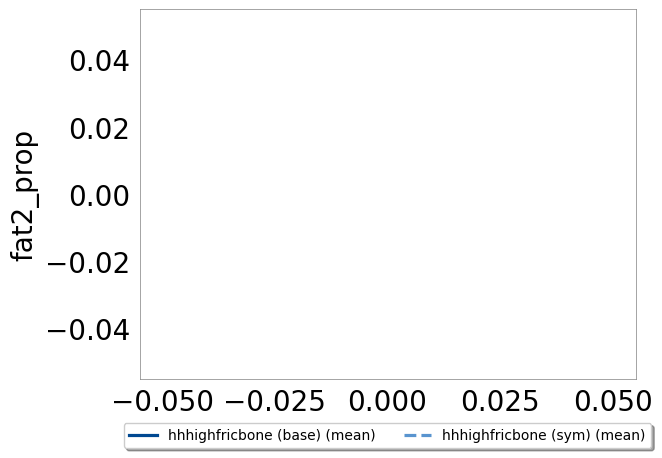

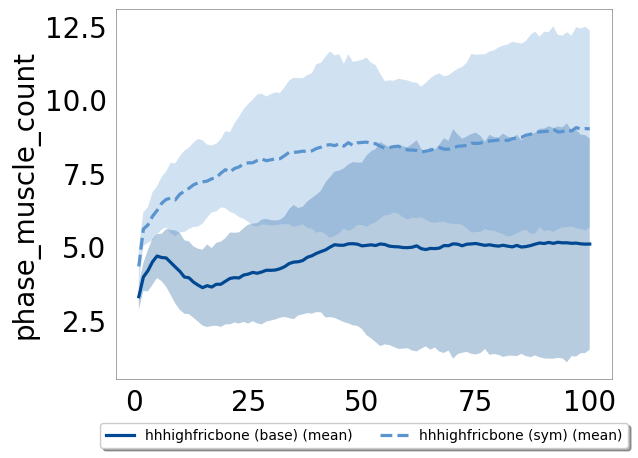

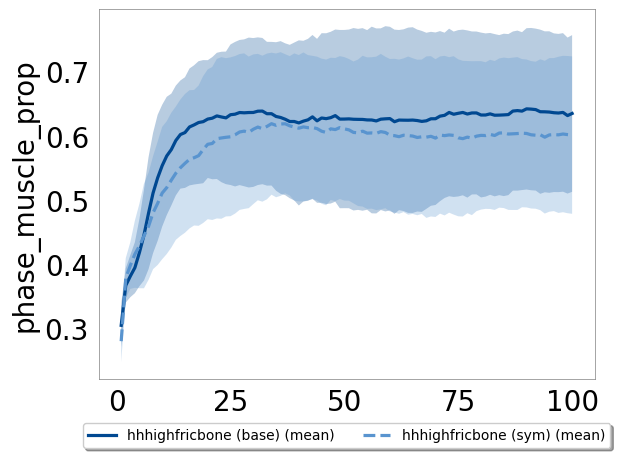

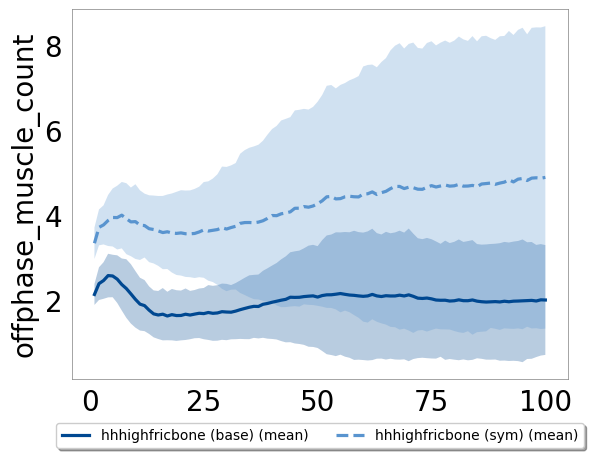

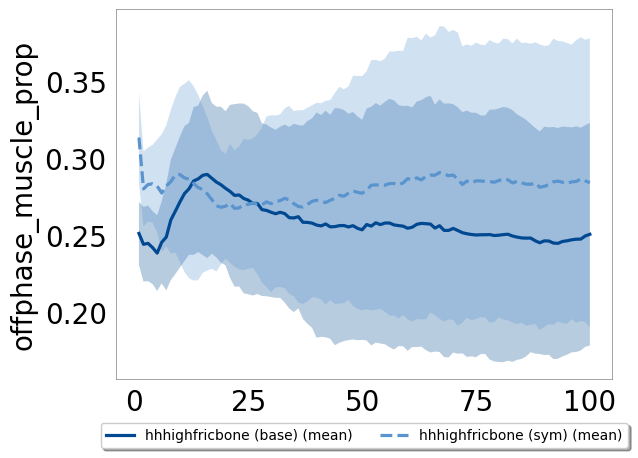

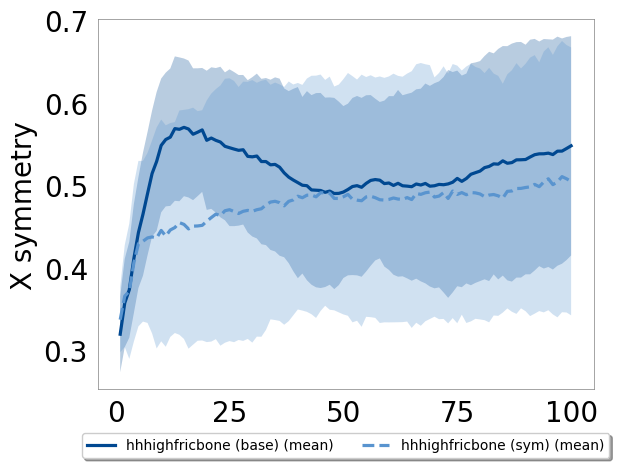

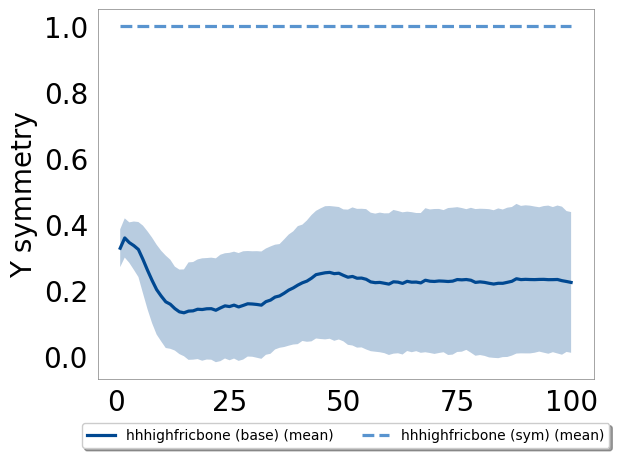

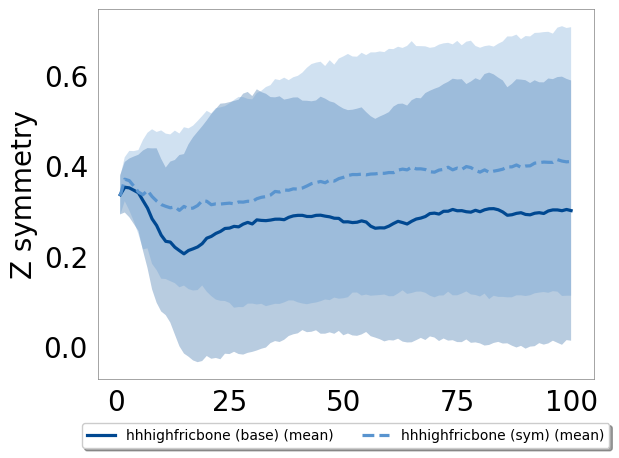

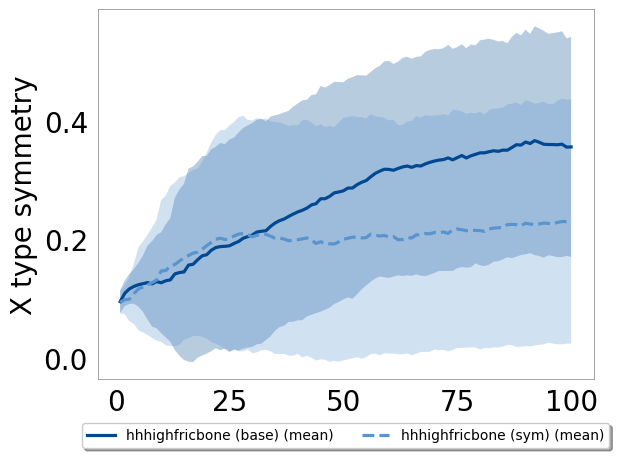

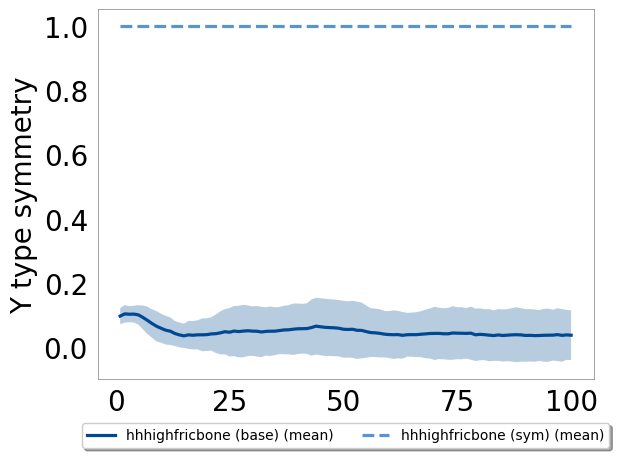

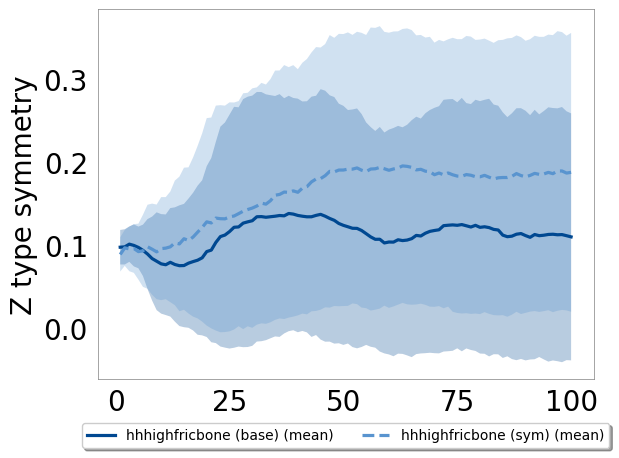

In [5]:
### Metrics progression ###

metrics =  [
    "fitness",
    "uniqueness",
    "age",
    "genome_size",
    "displacement",
    "num_voxels",
    "bone_count",
    "bone_prop",
    "fat_count",
    "fat_prop",
    "fat2_count",
    "fat2_prop",
    "phase_muscle_count",
    "phase_muscle_prop",
    "offphase_muscle_count",
    "offphase_muscle_prop",
]
metrics_labels =  [
"fitness",
    "uniqueness",
    "age",
    "genome_size",
    "displacement",
    "num_voxels",
    "bone_count",
    "bone_prop",
    "fat_count",
    "fat_prop",
    "fat2_count",
    "fat2_prop",
    "phase_muscle_count",
    "phase_muscle_prop",
    "offphase_muscle_count",
    "offphase_muscle_prop",
]

SHOW_MAX_MODE = "fitness"

ENV_COLOR_FAMILIES = {
    "high": {
        "bone": "#005AB5",
        "nobone": "#56B4E9",
    },
    "low": {
        "bone": "#D55E00",
        "nobone": "#E69F00",
    },
}
FALLBACK_COLORS = ["#005AB5", "#56B4E9", "#D55E00", "#E69F00", "#009E73", "#CC79A7"]
BASE_SETUP_LINESTYLE = "-"
SYMMETRIC_SETUP_LINESTYLE = "--"

def shade_color(color, factor):
    rgb = np.array(mcolors.to_rgb(color))
    if factor >= 1.0:
        shaded = rgb + (1.0 - rgb) * (factor - 1.0)
    else:
        shaded = rgb * factor
    return tuple(np.clip(shaded, 0.0, 1.0))

def experiment_style(exp_key, idx_experiment):
    study, exp_name = split_experiment_key(exp_key)
    exp_name_lower = exp_name.lower()
    friction = "low" if "low" in exp_name_lower else "high" if "high" in exp_name_lower else None
    body = "nobone" if "nobone" in exp_name_lower else "bone" if "bone" in exp_name_lower else None
    base_color = ENV_COLOR_FAMILIES.get(friction, {}).get(body, FALLBACK_COLORS[idx_experiment % len(FALLBACK_COLORS)])
    if study == other_study_name:
        color = shade_color(base_color, 1.35)
        linestyle = SYMMETRIC_SETUP_LINESTYLE
    else:
        color = shade_color(base_color, 0.8)
        linestyle = BASE_SETUP_LINESTYLE
    return color, linestyle

def cols(prefix, flavor):
    if flavor == "median_iqr":
        return f'{prefix}_median', f'{prefix}_q25', f'{prefix}_q75'
    if flavor == "mean_std":
        return f'{prefix}_avg', f'{prefix}_std', f'{prefix}_std'
    raise ValueError(f"unknown plot flavor: {flavor}")

PLOT_FLAVORS = {
    "median_iqr": {
        "filename_suffix": "",
        "shade_label": "Q25-Q75",
    },
    "mean_std": {
        "filename_suffix": "_meanstd",
        "shade_label": "std",
    },
}

for plot_flavor, plot_config in PLOT_FLAVORS.items():
    for exp_idx, exp_name in enumerate(base_experiments):
        paired_experiment_keys = [
            experiment_key(study_name, exp_name),
            experiment_key(other_study_name, exp_name),
        ]

        for idm, metric in enumerate(metrics):
            font = {'font.size': 20}
            plt.rcParams.update(font)
            fig, ax = plt.subplots()

            plt.xlabel('')
            plt.ylabel(f'{metrics_labels[idm]}')
            ax.grid(False)
            for side in ('top','right','bottom','left'):
                ax.spines[side].set_color('grey')
                ax.spines[side].set_linewidth(0.5)
            ax.tick_params(axis='x', which='both', bottom=False, top=False, labelbottom=True)
            ax.tick_params(axis='y', which='both', left=False, right=False, labelleft=True)

            mean_prefix = f'{metric}_mean'
            mean_center_col, mean_low_col, mean_high_col = cols(mean_prefix, plot_flavor)

            show_max_this_metric = (
                (SHOW_MAX_MODE == "all") or
                (SHOW_MAX_MODE == "fitness" and metric == "fitness")
            )

            if show_max_this_metric:
                max_prefix = f'{metric}_max'
                max_center_col, max_low_col, max_high_col = cols(max_prefix, plot_flavor)

            for idx_curve, exp_key in enumerate(paired_experiment_keys):
                metric_exp = gens_robots_outer[gens_robots_outer['experiment_key'] == exp_key]
                if metric_exp.empty or mean_center_col not in metric_exp.columns:
                    continue

                color, linestyle = experiment_style(exp_key, exp_idx)
                x = metric_exp['generation']
                y = metric_exp[mean_center_col]
                if plot_flavor == "mean_std":
                    low = y - metric_exp[mean_low_col]
                    high = y + metric_exp[mean_high_col]
                else:
                    low = metric_exp[mean_low_col]
                    high = metric_exp[mean_high_col]

                ax.plot(
                    x, y,
                    label=f'{display_label(exp_key)} (mean)', c=color, linewidth=2.3, linestyle=linestyle
                )
                ax.fill_between(
                    x, low, high,
                    alpha=0.28, facecolor=color, edgecolor='none', linewidth=0
                )

                if show_max_this_metric and max_center_col in metric_exp.columns:
                    y_max = metric_exp[max_center_col]
                    if plot_flavor == "mean_std":
                        max_low = y_max - metric_exp[max_low_col]
                        max_high = y_max + metric_exp[max_high_col]
                    else:
                        max_low = metric_exp[max_low_col]
                        max_high = metric_exp[max_high_col]

                    ax.plot(
                        x, y_max,
                        label=f'{display_label(exp_key)} (max)', c=color, linewidth=1.2,
                        linestyle=':' if linestyle == BASE_SETUP_LINESTYLE else '-.'
                    )
                    ax.fill_between(
                        x, max_low, max_high,
                        alpha=0.16, facecolor=color, edgecolor='none', linewidth=0
                    )

            ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.1),
                      fancybox=True, shadow=True, ncol=4, fontsize=10)

            fig.savefig(
                f'{analysis_path}/progression_{exp_name}_{metric}{plot_config["filename_suffix"]}.png',
                dpi=300, bbox_inches='tight'
            )
            plt.show()
            plt.close(fig)
